# Predicting Term-Deposit Subscription with Cost-Sensitive Evaluation

**CSI 5810 Midterm Project — Group 3**
Andrew Aurand (G), Christina Carvalho (U), Cameron Clark (U), Tyler Donovan (U)

**Dataset:** Bank Marketing, UCI Machine Learning Repository, dataset ID 222
(`bank-additional-full.csv`, 41,188 client records, 20 input attributes, binary target `y`).

**Research question.** *Can we predict, before a call is placed, which clients of a Portuguese
retail bank will subscribe to a term deposit, and does using those predictions to target calls
reduce expected campaign cost compared with calling every client?*

**Task type.** Binary classification with an uncommon positive class (about 11% of clients subscribe),
evaluated with ranking metrics (PR-AUC, ROC-AUC), threshold metrics (precision, recall, F1,
balanced accuracy, confusion matrices), probability calibration (Brier score, expected calibration
error, reliability diagrams), and an explicit campaign cost model (cost per call vs. value per
subscription).

---
## How to run this notebook

1. Create an environment with Python 3.10 or newer and install the packages in `requirements.txt`
   (`pip install -r requirements.txt`). The notebook was developed with
   pandas 3.0, NumPy 1.26, scikit-learn 1.8, SciPy 1.17, and Matplotlib 3.10.
2. Download `bank+marketing.zip` from <https://archive.ics.uci.edu/dataset/222/bank+marketing>,
   unzip it, then unzip the inner `bank-additional.zip` so that
   `dataset/bank-additional/bank-additional-full.csv` exists next to the `code/` folder
   (or set the environment variable `BANK_DATA_PATH` to the CSV's location).
3. Run all cells from top to bottom (Kernel -> Restart & Run All). A full run takes roughly
   10-20 minutes on an 8-core laptop; set `BANK_FAST=1` in the environment for a 2-3 minute
   smoke test with reduced hyperparameter grids (results are then *not* the reported ones).
4. All figures, tables, and a `results.json` with every number quoted in the report are written
   to `outputs/` next to this notebook.

**Reproducibility.** Every random operation (train/test split, cross-validation folds, model seeds,
hyperparameter sampling, bootstrap resampling, permutation importance) uses the fixed seed
`SEED = 5810`. Random-forest and gradient-boosting fits are multithreaded; thread scheduling does not
change their results for the settings used here, so re-running reproduces the reported numbers exactly
up to floating-point rounding.

**Notebook organisation** (one section per stage of the data-science workflow):
1. Setup and configuration
2. Data acquisition and documentation
3. Data-quality audit
4. Exploratory data analysis
5. Data preparation and feature engineering
6. Baseline and comparison models (cross-validated model selection)
7. Held-out test evaluation with uncertainty
8. Probability calibration
9. Cost-sensitive evaluation (expected campaign cost and value)
10. Operating points and confusion matrices
11. Model interpretation
12. Error analysis and subgroup performance
13. Sensitivity analyses (leakage, temporal validation, class weighting)
14. Export of results and summary

## 1. Setup and configuration

In [1]:
import os, sys, json, time, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_curve, confusion_matrix, precision_score,
                             recall_score, f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Detect whether we run inside Jupyter (for display) or as a plain script (for smoke tests).
try:
    get_ipython()  # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")
    def display(obj):  # fallback when running as a script
        print(obj)

# ---- global configuration -------------------------------------------------------------------
SEED = 5810                      # single seed used for every random operation
FAST = os.environ.get("BANK_FAST", "0") == "1"   # reduced grids for quick smoke tests
np.random.seed(SEED)

# Cost model (illustrative, stated explicitly in the report; varied in a sensitivity analysis).
# Interpretation: each contacted client costs COST_CONTACT (agent time + telephony); each subscription
# is worth VALUE_SUB in expected net interest margin to the bank (e.g., a 5,000 EUR deposit at 1%).
COST_CONTACT = 5.0               # EUR per contacted client
VALUE_SUB = 50.0                 # EUR per subscription
COST_RATIO = COST_CONTACT / VALUE_SUB   # = 0.10 -> Bayes-optimal threshold for calibrated probabilities
COST_RATIOS_SENS = [0.05, 0.10, 0.20, 0.30]  # sensitivity grid for the cost ratio

# ---- paths ------------------------------------------------------------------------------------
NB_DIR = Path.cwd()
_candidates = [Path(os.environ["BANK_DATA_PATH"])] if os.environ.get("BANK_DATA_PATH") else []
_candidates += [NB_DIR / "../dataset/bank-additional/bank-additional-full.csv",
                NB_DIR / "dataset/bank-additional/bank-additional-full.csv"]
DATA_PATH = next((p for p in _candidates if p.is_file()), None)
assert DATA_PATH is not None, ("bank-additional-full.csv not found. Download bank+marketing.zip from "
                               "https://archive.ics.uci.edu/dataset/222/bank+marketing and unzip "
                               "bank-additional.zip into ../dataset/ (see README).")
OUT_DIR = NB_DIR / "outputs"
FIG_DIR, TAB_DIR = OUT_DIR / "figures", OUT_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")
print(f"Data file: {DATA_PATH.resolve()}")
print(f"FAST mode: {FAST} | SEED = {SEED} | cost per contact = {COST_CONTACT}, value per subscription = {VALUE_SUB}")
T0 = time.time()

Python 3.12.10 | pandas 3.0.1 | numpy 1.26.4 | scikit-learn 1.8.0 | scipy 1.17.1 | matplotlib 3.10.8
Data file: C:\Users\Andrew Aurand\ccsi5810_midterm_group\dataset\bank-additional\bank-additional-full.csv
FAST mode: False | SEED = 5810 | cost per contact = 5.0, value per subscription = 50.0


In [2]:
# ---- plotting style: IEEE column width is ~3.5 in, full width ~7.16 in ------------------------
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 110, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "legend.frameon": False,
})
# Categorical palette (colour-blind-safe order), with line style + marker as a second encoding so
# that identity never relies on colour alone (also readable in greyscale print).
C_NO, C_YES = "#2a78d6", "#eb6834"
MODEL_STYLE = {
    "Majority baseline":   dict(color="#898781", ls=":",  marker=None),
    "Logistic regression": dict(color="#2a78d6", ls="-",  marker="o"),
    "k-NN":                dict(color="#eb6834", ls="--", marker="s"),
    "Random forest":       dict(color="#1baf7a", ls="-.", marker="^"),
    "Gradient boosting":   dict(color="#eda100", ls="-",  marker="D"),
}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#0d366b"])

def finish_figure(fig, name):
    """Save a figure as PDF (vector, for LaTeX) and PNG (for quick viewing), then show/close it."""
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

def _esc(s):
    return (str(s).replace("\\", "\\textbackslash{}").replace("&", "\\&").replace("%", "\\%")
            .replace("_", "\\_").replace("#", "\\#"))

def save_table(df, name, float_fmt="{:.3f}", align=None, index=False):
    """Write a table as CSV (full precision) and as a booktabs LaTeX tabular for the report."""
    d = df.reset_index() if index else df
    d.to_csv(TAB_DIR / f"{name}.csv", index=False)
    cols = list(d.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    lines = ["\\begin{tabular}{" + align + "}", "\\toprule",
             " & ".join(_esc(c) for c in cols) + " \\\\", "\\midrule"]
    for _, row in d.iterrows():
        cells = []
        for v in row:
            if isinstance(v, (float, np.floating)):
                cells.append("--" if np.isnan(v) else float_fmt.format(v))
            else:
                cells.append(_esc(v))
        lines.append(" & ".join(cells) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}"]
    (TAB_DIR / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")

RESULTS = {"seed": SEED, "fast_mode": FAST, "cost_contact": COST_CONTACT, "value_sub": VALUE_SUB,
           "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                        "numpy": np.__version__, "sklearn": sklearn.__version__}}

## 2. Data acquisition and documentation

| Item | Value |
|---|---|
| Dataset | Bank Marketing (with social/economic context), `bank-additional-full.csv` |
| Source | UCI Machine Learning Repository, dataset ID 222 (donated by S. Moro, P. Cortez, P. Rita) |
| Public URL | <https://archive.ics.uci.edu/dataset/222/bank+marketing> |
| Access date | 30 September 2026 |
| Size | 41,188 rows x 21 columns (20 inputs + target `y`) |
| Collection context | Direct-marketing phone campaigns of a Portuguese retail bank, May 2008 - November 2010; rows are ordered by date. Five macro-economic indicators (Banco de Portugal) were merged by date. |
| License | Creative Commons Attribution 4.0 (CC BY 4.0), as stated on the UCI page |
| Privacy | No direct identifiers; only coarse client attributes (age, job, education, loans) and campaign/contact metadata. |
| Known limitations | Single bank and country; campaigns concentrated in a financial-crisis period; the file is the "almost identical" public version of the data used in Moro et al. (2014), with some attributes withheld for privacy. |

The variable `duration` (seconds of the last call) is **not usable for prediction**: it is only known after the
call, and a call of zero seconds trivially implies `y = no`. The dataset documentation itself says it should be
discarded for a realistic model. We drop it (and quantify the leakage it would introduce in Section 13).

In [3]:
raw = pd.read_csv(DATA_PATH, sep=";")
raw["y_bin"] = (raw["y"] == "yes").astype(int)
print("shape:", raw.shape)

DESCRIPTIONS = {
    "age": "client age in years", "job": "type of job (12 levels)", "marital": "marital status",
    "education": "highest education level (8 levels)", "default": "has credit in default?",
    "housing": "has a housing loan?", "loan": "has a personal loan?",
    "contact": "contact communication type (cellular / telephone)",
    "month": "month of last contact", "day_of_week": "weekday of last contact",
    "duration": "last-call duration in seconds (LEAKAGE: known only after the call; dropped)",
    "campaign": "number of contacts in this campaign for this client (incl. last)",
    "pdays": "days since last contact in a previous campaign (999 = never contacted)",
    "previous": "number of contacts before this campaign",
    "poutcome": "outcome of the previous campaign (failure / nonexistent / success)",
    "emp.var.rate": "employment variation rate, quarterly (%)",
    "cons.price.idx": "consumer price index, monthly", "cons.conf.idx": "consumer confidence index, monthly",
    "euribor3m": "3-month Euribor rate, daily (%)", "nr.employed": "number of employees, quarterly (thousands)",
    "y": "TARGET: subscribed a term deposit? (yes / no)",
}
GROUPS = {**{c: "client" for c in ["age", "job", "marital", "education", "default", "housing", "loan"]},
          **{c: "last contact" for c in ["contact", "month", "day_of_week", "duration"]},
          **{c: "campaign history" for c in ["campaign", "pdays", "previous", "poutcome"]},
          **{c: "macro-economic" for c in ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]},
          "y": "target"}

rows = []
for c in raw.columns.drop("y_bin"):
    s = raw[c]
    numeric = pd.api.types.is_numeric_dtype(s)
    rows.append({"variable": c, "group": GROUPS[c], "type": "numeric" if numeric else "categorical",
                 "levels / range": f"{s.min()} - {s.max()}" if numeric else f"{s.nunique()} levels",
                 "unknown": int((s == "unknown").sum()) if not numeric else 0,
                 "description": DESCRIPTIONS[c]})
data_dictionary = pd.DataFrame(rows)
save_table(data_dictionary, "data_dictionary", align="llllrl")
display(data_dictionary)

shape: (41188, 22)


,variable,group,type,levels / range,unknown,description
0,age,client,numeric,17 - 98,0,client age in years
1,job,client,categorical,12 levels,330,type of job (12 levels)
2,marital,client,categorical,4 levels,80,marital status
3,education,client,categorical,8 levels,1731,highest education level (8 levels)
4,default,client,categorical,3 levels,8597,has credit in default?
5,housing,client,categorical,3 levels,990,has a housing loan?
6,loan,client,categorical,3 levels,990,has a personal loan?
7,contact,last contact,categorical,2 levels,0,contact communication type (cellular / telephone)
8,month,last contact,categorical,10 levels,0,month of last contact
9,day_of_week,last contact,categorical,5 levels,0,weekday of last contact


## 3. Data-quality audit

We check for exact duplicates, missing values coded as `unknown`, sentinel values (`pdays = 999`),
extreme values, class imbalance, and leakage. Each finding is tied to a preparation decision in Section 5.

In [4]:
audit = {}
audit["rows"] = len(raw)
audit["duplicate_rows"] = int(raw.drop(columns="y_bin").duplicated().sum())
audit["positive_rate"] = float(raw["y_bin"].mean())
audit["n_positive"] = int(raw["y_bin"].sum())
audit["pdays_999_share"] = float((raw["pdays"] == 999).mean())
audit["duration_zero_rows"] = int((raw["duration"] == 0).sum())
audit["duration_zero_all_no"] = bool((raw.loc[raw["duration"] == 0, "y"] == "no").all())
# How much of the target would `duration` alone explain?  (a single-feature ranking AUC)
audit["duration_alone_auc"] = float(roc_auc_score(raw["y_bin"], raw["duration"]))
audit["campaign_gt_10"] = int((raw["campaign"] > 10).sum())
audit["campaign_max"] = int(raw["campaign"].max())
audit["age_gt_80"] = int((raw["age"] > 80).sum())
audit["default_yes"] = int((raw["default"] == "yes").sum())
unknown_counts = {c: int((raw[c] == "unknown").sum()) for c in raw.columns
                  if not pd.api.types.is_numeric_dtype(raw[c])}
unknown_counts = {k: v for k, v in unknown_counts.items() if v > 0}
audit["unknown_counts"] = unknown_counts
audit["rows_with_any_unknown"] = int((raw[list(unknown_counts)] == "unknown").any(axis=1).sum())
RESULTS["audit"] = audit

audit_table = pd.DataFrame([
    ("Rows / columns", f"{audit['rows']:,} / 21"),
    ("Exact duplicate rows", f"{audit['duplicate_rows']} (dropped)"),
    ("Positive class (y = yes)", f"{audit['n_positive']:,} ({100*audit['positive_rate']:.1f}%)"),
    ("Rows with any 'unknown' value", f"{audit['rows_with_any_unknown']:,} ({100*audit['rows_with_any_unknown']/audit['rows']:.1f}%)"),
    ("'unknown' by column", ", ".join(f"{k} {v:,}" for k, v in sorted(unknown_counts.items(), key=lambda kv: -kv[1]))),
    ("pdays = 999 (never contacted before)", f"{100*audit['pdays_999_share']:.1f}% of rows"),
    ("duration = 0 s", f"{audit['duration_zero_rows']} rows, all y = no"),
    ("ROC-AUC of duration alone", f"{audit['duration_alone_auc']:.3f} (leakage; feature dropped)"),
    ("campaign > 10 contacts", f"{audit['campaign_gt_10']} rows (max {audit['campaign_max']})"),
    ("age > 80", f"{audit['age_gt_80']} rows"),
    ("default = yes", f"{audit['default_yes']} rows (level kept, effectively 'no' vs 'unknown')"),
], columns=["check", "finding"])
save_table(audit_table, "quality_audit", align="p{0.42\\linewidth}p{0.52\\linewidth}")
display(audit_table)

,check,finding
0,Rows / columns,"41,188 / 21"
1,Exact duplicate rows,12 (dropped)
2,Positive class (y = yes),"4,640 (11.3%)"
3,Rows with any 'unknown' value,"10,700 (26.0%)"
4,'unknown' by column,"default 8,597, education 1,731, housing 990, l..."
5,pdays = 999 (never contacted before),96.3% of rows
6,duration = 0 s,"4 rows, all y = no"
7,ROC-AUC of duration alone,0.818 (leakage; feature dropped)
8,campaign > 10 contacts,869 rows (max 56)
9,age > 80,119 rows


**Findings.** The data are clean in the conventional sense (no NaNs, consistent coding), but four issues matter
for modelling: (i) `duration` is a post-outcome variable with a single-feature AUC above 0.8 and must be removed;
(ii) 12 exact duplicates are dropped; (iii) `unknown` is a missing-value code, most common in `default`
(about 21% of rows) and `education` (4%). Because missingness is plausibly informative (clients who do not
disclose default status subscribe less often), we keep `unknown` as its own category rather than imputing;
(iv) `pdays = 999` is a sentinel for "never contacted", which we convert into an indicator plus a cleaned day
count. Only 11.3% of clients subscribe, so accuracy is uninformative (a majority-class model is 88.7% accurate)
and we evaluate with precision/recall-based, probabilistic, and cost-based metrics.

## 4. Exploratory data analysis

### 4.1 Target distribution and the time structure of the file

,rate,n,first_month,nr_employed
time_decile,,,,
1,0.027677,4119,may,5191.000000
2,0.035203,4119,may,5195.278344
3,0.042243,4119,jun,5228.100000
4,0.066278,4119,jul,5228.100000
5,0.062409,4118,jul,5228.100000
6,0.054625,4119,aug,5222.485336
7,0.101724,4119,nov,5168.942413
8,0.119689,4119,apr,5099.100000
9,0.157320,4119,may,5094.396577


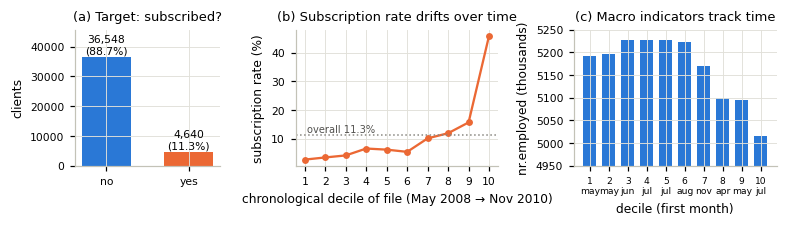

In [5]:
n_bins_time = 10
raw["time_decile"] = (np.arange(len(raw)) * n_bins_time // len(raw)) + 1
MONTH_ORDER = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
dec = raw.groupby("time_decile").agg(rate=("y_bin", "mean"), n=("y_bin", "size"),
                                     first_month=("month", "first"), nr_employed=("nr.employed", "mean"))
display(dec)
RESULTS["eda"] = {"rate_by_time_decile": dec["rate"].round(4).tolist(),
                  "first_decile_rate": float(dec["rate"].iloc[0]), "last_decile_rate": float(dec["rate"].iloc[-1])}

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.1), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
ax = axes[0]
counts = raw["y"].value_counts()
bars = ax.bar(["no", "yes"], [counts["no"], counts["yes"]], color=[C_NO, C_YES], width=0.6)
for b, v in zip(bars, [counts["no"], counts["yes"]]):
    ax.text(b.get_x() + b.get_width() / 2, v + 400, f"{v:,}\n({100*v/len(raw):.1f}%)", ha="center", va="bottom", fontsize=7)
ax.set_ylim(0, counts.max() * 1.25); ax.set_ylabel("clients"); ax.set_title("(a) Target: subscribed?")
ax = axes[1]
ax.plot(dec.index, 100 * dec["rate"], color=C_YES, marker="o", ms=3.5, lw=1.5)
ax.axhline(100 * raw["y_bin"].mean(), color="#898781", ls=":", lw=1)
ax.text(1.1, 100 * raw["y_bin"].mean() + 1, "overall 11.3%", fontsize=6.5, color="#52514e")
ax.set_xlabel("chronological decile of file (May 2008 → Nov 2010)"); ax.set_ylabel("subscription rate (%)")
ax.set_title("(b) Subscription rate drifts over time"); ax.set_xticks(dec.index)
ax = axes[2]
ax.bar(dec.index, dec["nr_employed"] - 4950, bottom=4950, color=C_NO, width=0.7)
ax.set_xlabel("decile (first month)"); ax.set_ylabel("nr.employed (thousands)")
ax.set_title("(c) Macro indicators track time"); ax.set_xticks(dec.index)
ax.set_xticklabels([f"{i}\n{m}" for i, m in zip(dec.index, dec["first_month"])], fontsize=6)
ax.set_ylim(4950, 5250)
fig.tight_layout(w_pad=1.5)
finish_figure(fig, "fig_target_time")

### 4.2 Distributions of important numerical variables by class

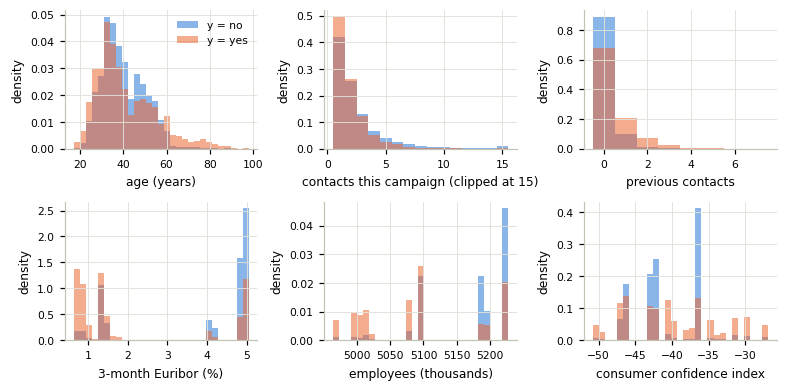

y                           no      yes
age            mean      39.91    40.91
               median    38.00    37.00
campaign       mean       2.63     2.05
               median     2.00     2.00
previous       mean       0.13     0.49
               median     0.00     0.00
emp.var.rate   mean       0.25    -1.23
               median     1.10    -1.80
cons.price.idx mean      93.60    93.35
               median    93.92    93.20
cons.conf.idx  mean     -40.59   -39.79
               median   -41.80   -40.40
euribor3m      mean       3.81     2.12
               median     4.86     1.27
nr.employed    mean    5176.17  5095.12
               median  5195.80  5099.10

In [6]:
num_show = [("age", None, "age (years)"), ("campaign", 15, "contacts this campaign (clipped at 15)"),
            ("previous", None, "previous contacts"), ("euribor3m", None, "3-month Euribor (%)"),
            ("nr.employed", None, "employees (thousands)"), ("cons.conf.idx", None, "consumer confidence index")]
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.6))
for ax, (col, clip, label) in zip(axes.ravel(), num_show):
    v = raw[col].clip(upper=clip) if clip else raw[col]
    bins = np.linspace(v.min(), v.max(), 30) if col not in ("previous", "campaign") else np.arange(v.min(), v.max() + 2) - 0.5
    for cls, color, name in [(0, C_NO, "no"), (1, C_YES, "yes")]:
        ax.hist(v[raw["y_bin"] == cls], bins=bins, density=True, alpha=0.55, color=color, label=f"y = {name}")
    ax.set_xlabel(label); ax.set_ylabel("density")
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
finish_figure(fig, "fig_numeric_by_class")

num_summary = raw.groupby("y")[["age", "campaign", "previous", "emp.var.rate", "cons.price.idx",
                                 "cons.conf.idx", "euribor3m", "nr.employed"]].agg(["mean", "median"]).T
display(num_summary.round(2))

### 4.3 Subscription rate by categorical variables

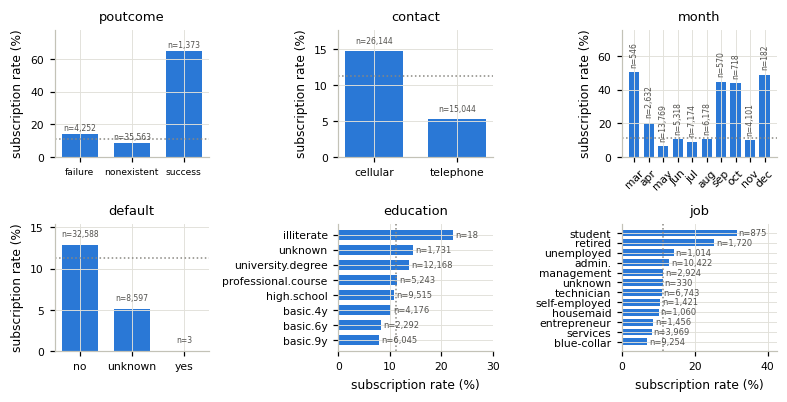

In [7]:
overall = raw["y_bin"].mean()
cat_specs = [("poutcome", None), ("contact", None), ("month", MONTH_ORDER), ("default", None),
             ("education", "sorted"), ("job", "sorted")]
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.7))
cat_rate_tables = {}
for ax, (col, order) in zip(axes.ravel(), cat_specs):
    g = raw.groupby(col)["y_bin"].agg(rate="mean", n="size")
    if order == "sorted":
        g = g.sort_values("rate")
    elif order is not None:
        g = g.loc[[m for m in order if m in g.index]]
    cat_rate_tables[col] = g
    horizontal = col in ("job", "education")
    if horizontal:
        ax.barh(g.index, 100 * g["rate"], color=C_NO, height=0.7)
        ax.axvline(100 * overall, color="#898781", ls=":", lw=1)
        for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
            ax.text(100 * r + 0.5, i, f"n={n:,}", va="center", fontsize=5.5, color="#52514e")
        ax.set_xlabel("subscription rate (%)"); ax.set_xlim(0, 100 * g["rate"].max() * 1.35)
    else:
        ax.bar(g.index, 100 * g["rate"], color=C_NO, width=0.7)
        ax.axhline(100 * overall, color="#898781", ls=":", lw=1)
        rot = 90 if col == "month" else 0
        for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
            ax.text(i, 100 * r + (3 if col == "month" else 0.8), f"n={n:,}", ha="center", va="bottom",
                    fontsize=5, color="#52514e", rotation=rot)
        ax.set_ylabel("subscription rate (%)"); ax.set_ylim(0, 100 * g["rate"].max() * (1.5 if col == "month" else 1.2))
        if col == "month":
            ax.tick_params(axis="x", labelrotation=45)
        if col == "poutcome":
            ax.tick_params(axis="x", labelsize=6)
    ax.set_title(col)
fig.tight_layout()
finish_figure(fig, "fig_categorical_rates")

cat_rates_long = pd.concat([t.assign(variable=c).reset_index().rename(columns={c: "level"}) for c, t in cat_rate_tables.items()])
cat_rates_long = cat_rates_long[["variable", "level", "n", "rate"]]
save_table(cat_rates_long, "subscription_rate_by_category")
RESULTS["eda"]["rate_by_poutcome"] = cat_rate_tables["poutcome"]["rate"].round(4).to_dict()
RESULTS["eda"]["rate_by_contact"] = cat_rate_tables["contact"]["rate"].round(4).to_dict()
RESULTS["eda"]["rate_by_month"] = cat_rate_tables["month"]["rate"].round(4).to_dict()
RESULTS["eda"]["n_by_month"] = cat_rate_tables["month"]["n"].to_dict()
RESULTS["eda"]["rate_by_job"] = cat_rate_tables["job"]["rate"].round(4).to_dict()
RESULTS["eda"]["rate_by_default"] = cat_rate_tables["default"]["rate"].round(4).to_dict()

### 4.4 Correlation and association analysis

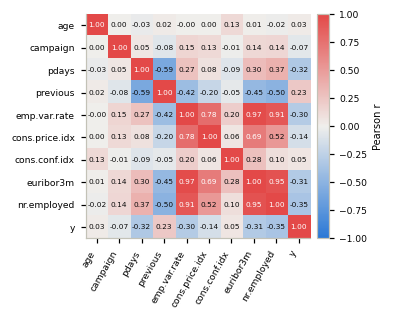

,variable,type,statistic,value
0,nr.employed,numeric,point-biserial r,-0.354678
1,pdays,numeric,point-biserial r,-0.324914
2,poutcome,categorical,Cramer's V,0.320488
3,euribor3m,numeric,point-biserial r,-0.307771
4,emp.var.rate,numeric,point-biserial r,-0.298334
5,month,categorical,Cramer's V,0.274395
6,previous,numeric,point-biserial r,0.230181
7,job,categorical,Cramer's V,0.152768
8,contact,categorical,Cramer's V,0.144773
9,cons.price.idx,numeric,point-biserial r,-0.136211


In [8]:
NUM_RAW = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
corr = raw[NUM_RAW + ["y_bin"]].rename(columns={"y_bin": "y"}).corr(method="pearson")
fig, ax = plt.subplots(figsize=(3.5, 3.1))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=6); ax.set_yticklabels(corr.columns, fontsize=6)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=4.8,
                color="white" if abs(corr.values[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(labelsize=6); cb.set_label("Pearson r", fontsize=6.5)
fig.tight_layout()
finish_figure(fig, "fig_correlation")

# Association of every input with the target: point-biserial r for numeric, Cramer's V for categorical.
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))

assoc_rows = []
for c in NUM_RAW:
    assoc_rows.append({"variable": c, "type": "numeric", "statistic": "point-biserial r",
                       "value": float(stats.pointbiserialr(raw["y_bin"], raw[c])[0])})
for c in ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]:
    assoc_rows.append({"variable": c, "type": "categorical", "statistic": "Cramer's V", "value": cramers_v(raw[c], raw["y"])})
assoc = pd.DataFrame(assoc_rows)
assoc["abs"] = assoc["value"].abs()
assoc = assoc.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)
save_table(assoc, "target_association")
display(assoc)
RESULTS["eda"]["association"] = {r.variable: round(r.value, 4) for r in assoc.itertuples()}
RESULTS["eda"]["corr_euribor_nr_employed"] = float(corr.loc["euribor3m", "nr.employed"])
RESULTS["eda"]["corr_euribor_empvar"] = float(corr.loc["euribor3m", "emp.var.rate"])

**Interpretation of the EDA.**
* **Imbalance and drift.** 11.3% of clients subscribe overall, but the rate rises from about 3% in the earliest
  decile of the file (May-June 2008, high call volume) to about 31% in the last decile (2010, far fewer, more
  selective calls). The campaign changed over time, so time-ordered validation is an important robustness check.
* **Strongest single predictors.** The outcome of the previous campaign (`poutcome = success` yields a 65%
  rate vs. 9% for clients never contacted), the contact channel (cellular 15% vs. telephone 5%), and the month
  of contact (rates above 40% in Mar/Sep/Oct/Dec, which are low-volume months) carry the most signal among
  categorical variables. Among numeric variables, the macro-economic indicators (`euribor3m`, `nr.employed`,
  `emp.var.rate`) have the largest correlations with the target; low interest rates and low employment
  (the 2009-2010 crisis period) coincide with higher subscription rates.
* **Collinearity.** `euribor3m`, `nr.employed` and `emp.var.rate` are almost perfectly correlated
  (r > 0.9), because they vary only quarter-to-quarter. They act mainly as proxies for *when* a client was
  called; a linear model cannot separate their effects.
* **Client attributes are weak but sensible.** Students and retired clients (31% and 25%) subscribe far more
  than blue-collar workers (7%); the age distribution of subscribers is bimodal (under 30 and over 60).
* **Data quality.** `default = unknown` is associated with a low rate (5%), supporting the decision to keep
  `unknown` as a category. `campaign` is right-skewed: a few clients were called more than 20 times, almost
  always without success.

## 5. Data preparation and feature engineering

Decisions (each justified by the audit above):
1. **Drop `duration`** (target leakage; known only after the call).
2. **Drop 12 exact duplicate rows.**
3. **`pdays`:** replace the sentinel 999 by 0 and add a binary `prev_contacted` indicator, so linear models
   are not distorted by the sentinel and tree models keep the information.
4. **`unknown` kept as a category** (informative missingness; no imputation).
5. **Outliers:** kept. Tree models are insensitive to them; for the linear model, standardisation keeps the
   scale manageable and the few extreme `campaign` values are genuine (clients called many times).
6. **Encoding/scaling inside pipelines.** One-hot encoding (`handle_unknown="ignore"`) and standard scaling
   for the linear and distance-based models; one-hot without scaling for the random forest; ordinal codes with
   native categorical handling for gradient boosting. Because every transformer sits inside a scikit-learn
   `Pipeline`, it is fitted only on the training portion of each fold, which prevents leakage from validation
   or test data.
7. **Split:** stratified 80/20 train/test split (`random_state = SEED`). The test set is used once, at the end.
   All model selection (hyperparameters, decision thresholds, calibration maps) uses 5-fold stratified
   cross-validation *inside the training set*.

In [9]:
df = raw.drop(columns=["y_bin", "time_decile"]).drop_duplicates().reset_index(drop=False).rename(columns={"index": "orig_row"})
df["y"] = (df["y"] == "yes").astype(int)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays"] = df["pdays"].where(df["pdays"] != 999, 0)

LEAK = ["duration"]
NUM = ["age", "campaign", "pdays", "previous", "prev_contacted",
       "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CAT = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
FEATURES = NUM + CAT
for c in CAT:                       # plain Python strings keep the encoders' category names readable
    df[c] = df[c].astype(object)

X, y = df[FEATURES], df["y"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"after de-duplication: {len(df):,} rows | train {len(X_train):,} ({y_train.mean():.4f} positive) | "
      f"test {len(X_test):,} ({y_test.mean():.4f} positive)")
RESULTS["split"] = {"n_total": int(len(df)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
                    "train_pos_rate": float(y_train.mean()), "test_pos_rate": float(y_test.mean()),
                    "n_test_pos": int(y_test.sum())}

def make_preprocessor(kind, num_cols=None):
    """kind = 'linear' (scale + one-hot), 'tree' (one-hot only), 'hgb' (ordinal codes + native categoricals)."""
    num_cols = NUM if num_cols is None else num_cols
    if kind == "linear":
        return ColumnTransformer([("num", StandardScaler(), num_cols),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    if kind == "tree":
        return ColumnTransformer([("num", "passthrough", num_cols),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    if kind == "hgb":
        return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CAT),
                                  ("num", "passthrough", num_cols)])
    raise ValueError(kind)

PRE_KIND = {"Logistic regression": "linear", "k-NN": "linear", "Random forest": "tree", "Gradient boosting": "hgb"}

after de-duplication: 41,176 rows | train 32,940 (0.1127 positive) | test 8,236 (0.1127 positive)


## 6. Baseline and comparison models

| Model | Why it is appropriate | Main assumptions | Tuned hyperparameters |
|---|---|---|---|
| **Majority-class baseline** | Floor for every metric; shows that accuracy is meaningless at 11% prevalence | none | none |
| **Logistic regression** | Interpretable linear baseline; well-calibrated probabilities by construction; fast | log-odds linear in the (one-hot) features; independence of observations | L2 strength `C` |
| **k-nearest neighbours** | Non-parametric, distance-based reference covered in the course | local smoothness in standardised feature space; all features equally relevant | `n_neighbors`, `weights` |
| **Random forest** | Captures interactions/non-linearity, robust to outliers and scaling, few assumptions | bagged axis-aligned splits generalise; probabilities = vote fractions (often under-confident) | `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient boosting (histogram)** | State of the art on tabular data; native categorical handling; strong ranking | additive trees fitted to log-loss gradients; needs regularisation to avoid over-fitting | `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization`, `max_iter` |

**Model-selection protocol.** 5-fold stratified cross-validation on the training set with
**average precision (PR-AUC)** as the selection score, because it focuses on the rare positive class and
is threshold-free. ROC-AUC and the Brier score are recorded alongside. Hyperparameters are chosen by grid
search (small grids) or randomised search (larger grids), always with the same folds and seed.
Class weighting is deliberately *not* part of the main configuration; its effect is studied in Section 13.

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"ap": "average_precision", "auc": "roc_auc", "brier": "neg_brier_score"}

model_specs = {
    "Logistic regression": dict(
        pipe=Pipeline([("pre", make_preprocessor("linear")),
                       ("clf", LogisticRegression(max_iter=3000, solver="lbfgs"))]),
        grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]}, search="grid"),
    "k-NN": dict(
        pipe=Pipeline([("pre", make_preprocessor("linear")), ("clf", KNeighborsClassifier())]),
        grid={"clf__n_neighbors": [25, 51, 101, 201], "clf__weights": ["uniform", "distance"]}, search="grid"),
    "Random forest": dict(
        pipe=Pipeline([("pre", make_preprocessor("tree")),
                       ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1))]),
        grid={"clf__max_depth": [8, 12, 16, None], "clf__min_samples_leaf": [1, 5, 20],
              "clf__max_features": ["sqrt", 0.3, 0.5]}, search="random", n_iter=18),
    "Gradient boosting": dict(
        pipe=Pipeline([("pre", make_preprocessor("hgb")),
                       ("clf", HistGradientBoostingClassifier(categorical_features=list(range(len(CAT))),
                                                              random_state=SEED, early_stopping=False))]),
        grid={"clf__learning_rate": [0.03, 0.06, 0.1], "clf__max_leaf_nodes": [15, 31, 63],
              "clf__min_samples_leaf": [20, 50, 100], "clf__l2_regularization": [0.0, 1.0, 5.0],
              "clf__max_iter": [150, 300, 500]}, search="random", n_iter=24),
}
if FAST:   # smoke-test settings: tiny grids and small forests
    model_specs["Logistic regression"]["grid"] = {"clf__C": [0.3]}
    model_specs["k-NN"]["grid"] = {"clf__n_neighbors": [101], "clf__weights": ["uniform"]}
    model_specs["Random forest"]["n_iter"] = 2
    model_specs["Random forest"]["pipe"].set_params(clf__n_estimators=50)
    model_specs["Gradient boosting"]["n_iter"] = 3

fitted, cv_rows = {}, []
# --- majority-class baseline (no tuning): predicts "no" for everyone and the class prior (0.113) as the
#     probability, so that probabilistic metrics (AP, Brier, log loss) are also well defined for it ---
dummy = DummyClassifier(strategy="prior")
cvd = cross_validate(dummy, X_train, y_train, cv=skf, scoring=SCORING)
fitted["Majority baseline"] = dummy.fit(X_train, y_train)
cv_rows.append({"model": "Majority baseline", "selected hyperparameters": "none",
                "AP mean": cvd["test_ap"].mean(), "AP sd": cvd["test_ap"].std(),
                "ROC-AUC mean": cvd["test_auc"].mean(), "ROC-AUC sd": cvd["test_auc"].std(),
                "Brier mean": -cvd["test_brier"].mean(), "Brier sd": cvd["test_brier"].std(), "fit s": 0.0})

search_objects = {}
for name, spec in model_specs.items():
    t = time.time()
    if spec["search"] == "grid":
        search = GridSearchCV(spec["pipe"], spec["grid"], scoring=SCORING, refit="ap", cv=skf, n_jobs=-1)
    else:
        search = RandomizedSearchCV(spec["pipe"], spec["grid"], n_iter=spec["n_iter"], scoring=SCORING,
                                    refit="ap", cv=skf, n_jobs=-1, random_state=SEED)
    search.fit(X_train, y_train)
    i = search.best_index_
    r = search.cv_results_
    best = search.best_estimator_
    if name == "Random forest":          # parallel trees for the refitted model (results unchanged)
        best.set_params(clf__n_jobs=-1)
    fitted[name] = best
    search_objects[name] = search
    params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    cv_rows.append({"model": name, "selected hyperparameters": ", ".join(f"{k}={v}" for k, v in params.items()),
                    "AP mean": r["mean_test_ap"][i], "AP sd": r["std_test_ap"][i],
                    "ROC-AUC mean": r["mean_test_auc"][i], "ROC-AUC sd": r["std_test_auc"][i],
                    "Brier mean": -r["mean_test_brier"][i], "Brier sd": r["std_test_brier"][i],
                    "fit s": time.time() - t})
    print(f"{name:20s} best CV AP = {r['mean_test_ap'][i]:.4f} +/- {r['std_test_ap'][i]:.4f} | "
          f"{len(r['mean_test_ap'])} configs | {time.time()-t:.0f} s | {params}")

cv_results = pd.DataFrame(cv_rows)
MODELS = list(cv_results["model"])
save_table(cv_results, "cv_results", float_fmt="{:.4f}")
display(cv_results)
# Compact "mean +/- sd" version for the report.
cv_lines = ["\\begin{tabular}{lccc}", "\\toprule", "model & AP & ROC-AUC & Brier \\\\", "\\midrule"]
for _, r in cv_results.iterrows():
    cv_lines.append(f"{r['model']} & {r['AP mean']:.3f} $\\pm$ {r['AP sd']:.3f} & {r['ROC-AUC mean']:.3f} $\\pm$ {r['ROC-AUC sd']:.3f} "
                    f"& {r['Brier mean']:.4f} $\\pm$ {r['Brier sd']:.4f} \\\\")
cv_lines += ["\\bottomrule", "\\end{tabular}"]
(TAB_DIR / "cv_results_report.tex").write_text("\n".join(cv_lines), encoding="utf-8")
BEST = cv_results.loc[cv_results["model"] != "Majority baseline"].sort_values("AP mean").iloc[-1]["model"]
print("Model selected by cross-validated AP:", BEST)
RESULTS["cv"] = cv_results.set_index("model").drop(columns="selected hyperparameters").round(4).to_dict("index")
RESULTS["best_model"] = BEST
RESULTS["best_params"] = {n: {k.replace("clf__", ""): (v if isinstance(v, (int, float, str)) or v is None else str(v))
                              for k, v in s.best_params_.items()} for n, s in search_objects.items()}

# Record the full search space (for the report appendix).
grid_rows = []
for name, spec in model_specs.items():
    for k, v in spec["grid"].items():
        grid_rows.append({"model": name, "hyperparameter": k.replace("clf__", ""), "candidates": str(v),
                          "selected": str(search_objects[name].best_params_[k])})
save_table(pd.DataFrame(grid_rows), "hyperparameter_grids", align="llll")

Logistic regression  best CV AP = 0.4531 +/- 0.0122 | 7 configs | 7 s | {'C': 3.0}


k-NN                 best CV AP = 0.4334 +/- 0.0160 | 8 configs | 10 s | {'n_neighbors': 201, 'weights': 'uniform'}


Random forest        best CV AP = 0.4693 +/- 0.0161 | 18 configs | 176 s | {'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 8}


Gradient boosting    best CV AP = 0.4717 +/- 0.0161 | 24 configs | 52 s | {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 150, 'learning_rate': 0.03, 'l2_regularization': 0.0}


,model,selected hyperparameters,AP mean,AP sd,ROC-AUC mean,ROC-AUC sd,Brier mean,Brier sd,fit s
0,Majority baseline,none,0.112659,0.000061,0.500000,0.000000,0.099967,0.000047,0.000000
1,Logistic regression,C=3.0,0.453090,0.012238,0.789737,0.009635,0.078439,0.001400,7.178380
2,k-NN,"n_neighbors=201, weights=uniform",0.433385,0.016047,0.782558,0.012071,0.079324,0.001483,10.495682
3,Random forest,"min_samples_leaf=5, max_features=0.5, max_depth=8",0.469343,0.016057,0.800601,0.012841,0.076542,0.001740,176.393151
4,Gradient boosting,"min_samples_leaf=100, max_leaf_nodes=15, max_i...",0.471658,0.016142,0.801871,0.011849,0.076537,0.001666,52.317631


Model selected by cross-validated AP: Gradient boosting


## 7. Held-out test evaluation with uncertainty

Threshold-free metrics on the untouched test set, with 95% bootstrap confidence intervals
(1,000 resamples of the test rows, same resamples for every model so that differences are paired).

In [11]:
P_TEST = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}

def ece_score(y_true, p, n_bins=10):
    """Expected calibration error with equal-width bins."""
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return float(ece)

METRICS = {"AP": average_precision_score, "ROC-AUC": roc_auc_score, "Brier": brier_score_loss,
           "log loss": log_loss, "ECE": ece_score}
N_BOOT = 200 if FAST else 1000
boot_rng = np.random.default_rng(SEED)
BOOT_IDX = [boot_rng.integers(0, len(y_test), len(y_test)) for _ in range(N_BOOT)]

def bootstrap_metric(y_true, p, fn):
    vals = [fn(y_true[i], p[i]) for i in BOOT_IDX]
    return np.percentile(vals, [2.5, 97.5])

test_rows, test_num = [], {}
for name in MODELS:
    p = P_TEST[name]
    row = {"model": name}
    test_num[name] = {}
    for mname, fn in METRICS.items():
        val = fn(y_test, p)
        lo, hi = bootstrap_metric(y_test, p, fn) if name != "Majority baseline" else (val, val)
        row[mname] = f"{val:.3f} [{lo:.3f}, {hi:.3f}]"
        test_num[name][mname] = {"value": float(val), "ci_low": float(lo), "ci_high": float(hi)}
    test_rows.append(row)
test_metrics = pd.DataFrame(test_rows)
save_table(test_metrics, "test_metrics_ci", align="lccccc")
display(test_metrics)
RESULTS["test"] = test_num
# Compact report version: three headline metrics with 95% CIs.
save_table(test_metrics[["model", "AP", "ROC-AUC", "Brier"]], "test_metrics_report", align="lccc")

def write_tex_table(name, align, header, rows):
    """Write a booktabs tabular whose cells may already contain LaTeX (no escaping)."""
    lines = ["\\begin{tabular}{" + align + "}", "\\toprule", " & ".join(header) + " \\\\", "\\midrule"]
    lines += [" & ".join(r) + " \\\\" for r in rows]
    lines += ["\\bottomrule", "\\end{tabular}"]
    (TAB_DIR / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")

# Combined model-comparison table for the report: cross-validated AP and test metrics with 95% CIs.
cvi = cv_results.set_index("model"); tmi = test_metrics.set_index("model")
write_tex_table("model_comparison_report", "lcccc",
                ["model", "CV AP (mean $\\pm$ sd)", "test AP [95\\% CI]", "test ROC-AUC [95\\% CI]", "test Brier [95\\% CI]"],
                [[m, f"{cvi.loc[m, 'AP mean']:.3f} $\\pm$ {cvi.loc[m, 'AP sd']:.3f}", tmi.loc[m, "AP"], tmi.loc[m, "ROC-AUC"], tmi.loc[m, "Brier"]] for m in MODELS])

# Paired bootstrap for the AP difference between the selected model and each competitor.
diffs = {}
for other in MODELS:
    if other in (BEST, "Majority baseline"):
        continue
    d = [average_precision_score(y_test[i], P_TEST[BEST][i]) - average_precision_score(y_test[i], P_TEST[other][i]) for i in BOOT_IDX]
    diffs[other] = {"mean_diff": float(np.mean(d)), "ci_low": float(np.percentile(d, 2.5)), "ci_high": float(np.percentile(d, 97.5))}
    print(f"AP({BEST}) - AP({other}) = {np.mean(d):+.4f}  95% CI [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")
RESULTS["ap_paired_diff_vs_best"] = diffs

,model,AP,ROC-AUC,Brier,log loss,ECE
0,Majority baseline,"0.113 [0.113, 0.113]","0.500 [0.500, 0.500]","0.100 [0.100, 0.100]","0.352 [0.352, 0.352]","0.000 [0.000, 0.000]"
1,Logistic regression,"0.449 [0.416, 0.486]","0.796 [0.778, 0.814]","0.079 [0.074, 0.083]","0.277 [0.263, 0.291]","0.008 [0.007, 0.016]"
2,k-NN,"0.434 [0.400, 0.471]","0.791 [0.773, 0.807]","0.079 [0.075, 0.084]","0.283 [0.267, 0.301]","0.008 [0.007, 0.016]"
3,Random forest,"0.479 [0.444, 0.514]","0.806 [0.789, 0.823]","0.077 [0.072, 0.081]","0.270 [0.257, 0.284]","0.009 [0.006, 0.016]"
4,Gradient boosting,"0.481 [0.445, 0.515]","0.810 [0.794, 0.827]","0.076 [0.072, 0.081]","0.269 [0.256, 0.283]","0.005 [0.004, 0.013]"


AP(Gradient boosting) - AP(Logistic regression) = +0.0312  95% CI [+0.0180, +0.0446]


AP(Gradient boosting) - AP(k-NN) = +0.0463  95% CI [+0.0323, +0.0607]


AP(Gradient boosting) - AP(Random forest) = +0.0012  95% CI [-0.0080, +0.0099]


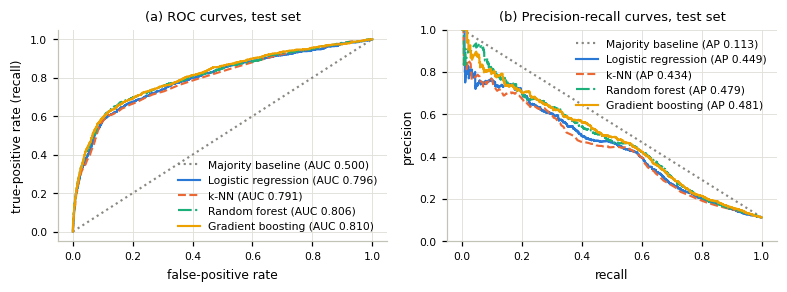

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
ax = axes[0]
for name in MODELS:
    st = MODEL_STYLE[name]
    fpr, tpr, _ = roc_curve(y_test, P_TEST[name])
    ax.plot(fpr, tpr, color=st["color"], ls=st["ls"], lw=1.4, label=f"{name} (AUC {test_num[name]['ROC-AUC']['value']:.3f})")
ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate (recall)"); ax.set_title("(a) ROC curves, test set")
ax.legend(loc="lower right")
ax = axes[1]
for name in MODELS:
    st = MODEL_STYLE[name]
    prec, rec, _ = precision_recall_curve(y_test, P_TEST[name])
    ax.plot(rec, prec, color=st["color"], ls=st["ls"], lw=1.4, label=f"{name} (AP {test_num[name]['AP']['value']:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("(b) Precision-recall curves, test set")
ax.set_ylim(0, 1); ax.legend(loc="upper right")
fig.tight_layout()
finish_figure(fig, "fig_roc_pr")

## 8. Probability calibration

A cost-based decision rule ("call a client if the probability of subscribing exceeds the cost ratio") is only
valid if the predicted probabilities are *calibrated*, i.e. among clients given probability 0.2, about 20%
subscribe. We assess calibration with reliability diagrams, the Brier score and the expected calibration error
(ECE), and we fit **isotonic regression** calibrators with 5-fold cross-validation *inside the training set*
(`CalibratedClassifierCV`), so the test set remains untouched.

calibrated Logistic regression in 1 s


calibrated k-NN in 5 s


calibrated Random forest in 11 s


calibrated Gradient boosting in 3 s


,model,Brier raw,Brier calibrated,ECE raw,ECE calibrated,AP raw,AP calibrated,mean p raw,mean p calibrated
0,Logistic regression,0.078562,0.078369,0.008347,0.003018,0.449434,0.448000,0.112345,0.112474
1,k-NN,0.079179,0.078892,0.008348,0.002436,0.434489,0.434073,0.110036,0.112111
2,Random forest,0.076569,0.076395,0.008818,0.003580,0.479466,0.479620,0.112659,0.112411
3,Gradient boosting,0.076288,0.076372,0.004864,0.004760,0.480804,0.477065,0.112640,0.112446


share of test clients with calibrated p > 0.7: {'Logistic regression': 0.0148, 'k-NN': 0.014, 'Random forest': 0.0178, 'Gradient boosting': 0.0148}


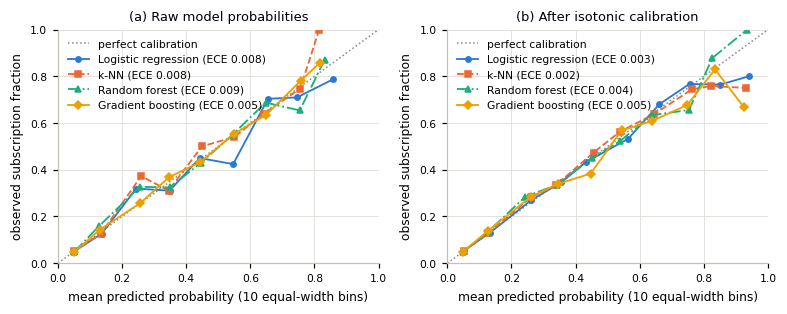

In [13]:
CALIBRATED = {}
for name in MODELS:
    if name == "Majority baseline":
        continue
    t = time.time()
    cal = CalibratedClassifierCV(clone(fitted[name]), method="isotonic", cv=skf, ensemble=True)
    cal.fit(X_train, y_train)
    CALIBRATED[name] = cal
    P_TEST[name + " (calibrated)"] = cal.predict_proba(X_test)[:, 1]
    print(f"calibrated {name} in {time.time()-t:.0f} s")

cal_rows = []
for name in CALIBRATED:
    p_raw, p_cal = P_TEST[name], P_TEST[name + " (calibrated)"]
    cal_rows.append({"model": name,
                     "Brier raw": brier_score_loss(y_test, p_raw), "Brier calibrated": brier_score_loss(y_test, p_cal),
                     "ECE raw": ece_score(y_test, p_raw), "ECE calibrated": ece_score(y_test, p_cal),
                     "AP raw": average_precision_score(y_test, p_raw), "AP calibrated": average_precision_score(y_test, p_cal),
                     "mean p raw": p_raw.mean(), "mean p calibrated": p_cal.mean()})
calibration_table = pd.DataFrame(cal_rows)
save_table(calibration_table, "calibration", float_fmt="{:.3f}")
display(calibration_table)
RESULTS["calibration"] = calibration_table.set_index("model").round(4).to_dict("index")
# How many test clients receive high probabilities?  (context for the noisy right end of the reliability diagrams)
RESULTS["share_test_clients_p_above_0.7"] = {name: float((P_TEST[name + " (calibrated)"] > 0.7).mean()) for name in CALIBRATED}
print("share of test clients with calibrated p > 0.7:", {k: round(v, 4) for k, v in RESULTS["share_test_clients_p_above_0.7"].items()})
# Compact report version (raw -> calibrated).
cal_rep = pd.DataFrame({"model": calibration_table["model"],
                        "Brier raw": calibration_table["Brier raw"].map("{:.4f}".format),
                        "Brier cal.": calibration_table["Brier calibrated"].map("{:.4f}".format),
                        "ECE raw": calibration_table["ECE raw"].map("{:.3f}".format),
                        "ECE cal.": calibration_table["ECE calibrated"].map("{:.3f}".format),
                        "AP cal.": calibration_table["AP calibrated"].map("{:.3f}".format)})
save_table(cal_rep, "calibration_report", align="lrrrrr")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
for ax, suffix, title in [(axes[0], "", "(a) Raw model probabilities"), (axes[1], " (calibrated)", "(b) After isotonic calibration")]:
    ax.plot([0, 1], [0, 1], color="#898781", ls=":", lw=1, label="perfect calibration")
    for name in CALIBRATED:
        st = MODEL_STYLE[name]
        p = P_TEST[name + suffix]
        frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="uniform")
        ax.plot(mean_pred, frac_pos, color=st["color"], ls=st["ls"], marker=st["marker"], ms=3.5, lw=1.2,
                label=f"{name} (ECE {ece_score(y_test, p):.3f})")
    ax.set_xlabel("mean predicted probability (10 equal-width bins)"); ax.set_ylabel("observed subscription fraction")
    ax.set_title(title); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left")
fig.tight_layout()
finish_figure(fig, "fig_calibration")

## 9. Cost-sensitive evaluation: expected campaign cost and value

**Decision rule.** Call client *i* if the predicted probability p_i >= t. Each call costs *c* (`COST_CONTACT`);
each subscription is worth *v* (`VALUE_SUB`). For a set of calls with TP true positives and FP false positives:

* campaign spend = c (TP + FP), subscriptions captured = TP,
* **net value** = v TP - c (TP + FP),
* **expected misclassification cost** (relative to perfect targeting) = c FP + (v - c) FN,
  i.e. wasted calls plus the margin lost on subscribers who were not called.

Maximising net value is equivalent to minimising this cost. If probabilities are calibrated, the Bayes-optimal
rule is to call whenever p_i v >= c, i.e. **t\* = c / v = 0.10** for our assumptions. For un-calibrated scores
we instead tune *t* on out-of-fold training predictions. We compare the model-targeted strategies with the
two naive policies "call everyone" (what the data describe) and "call nobody", and with a perfect-information
oracle. All quantities are reported **per 1,000 clients** so they do not depend on the test-set size.

In [14]:
THRESHOLDS = np.round(np.arange(0.01, 0.951, 0.01), 2)

def campaign_value(y_true, p, t, c=COST_CONTACT, v=VALUE_SUB):
    call = p >= t
    tp = int((call & (y_true == 1)).sum()); fp = int((call & (y_true == 0)).sum())
    fn = int((~call & (y_true == 1)).sum()); tn = int((~call & (y_true == 0)).sum())
    n = len(y_true); calls = tp + fp
    return {"threshold": float(t), "calls": calls, "call rate": calls / n, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": tp / calls if calls else 0.0, "recall": tp / (tp + fn) if (tp + fn) else 0.0,
            "spend per 1000": 1000 * c * calls / n, "subscriptions per 1000": 1000 * tp / n,
            "net value per 1000": 1000 * (v * tp - c * calls) / n,
            "misclassification cost per 1000": 1000 * (c * fp + (v - c) * fn) / n}

def value_curve(y_true, p, c=COST_CONTACT, v=VALUE_SUB):
    return np.array([campaign_value(y_true, p, t, c, v)["net value per 1000"] for t in THRESHOLDS])

# Out-of-fold probabilities on the training set -> threshold tuning without touching the test set.
P_OOF = {}
for name in MODELS:
    if name == "Majority baseline":
        continue
    t0 = time.time()
    P_OOF[name] = cross_val_predict(clone(fitted[name]), X_train, y_train, cv=skf, method="predict_proba")[:, 1]
    print(f"OOF predictions for {name}: {time.time()-t0:.0f} s")

T_STAR = COST_RATIO
T_TUNED = {name: float(THRESHOLDS[np.argmax(value_curve(y_train, P_OOF[name]))]) for name in P_OOF}
print("Bayes threshold t* =", T_STAR, "| OOF-tuned thresholds:", T_TUNED)

# Strategies compared on the test set.
n_test, pos_test = len(y_test), int(y_test.sum())
strategy_rows = [
    {"strategy": "Call nobody", **{k: v for k, v in campaign_value(y_test, np.zeros(n_test), 0.5).items() if k != "threshold"}},
    {"strategy": "Call everyone (current practice)", **{k: v for k, v in campaign_value(y_test, np.ones(n_test), 0.5).items() if k != "threshold"}},
    {"strategy": "Oracle (perfect information)", **{k: v for k, v in campaign_value(y_test, y_test.astype(float), 0.5).items() if k != "threshold"}},
]
for name in P_OOF:
    strategy_rows.append({"strategy": f"{name}, raw, t = 0.5", **campaign_value(y_test, P_TEST[name], 0.5)})
    strategy_rows.append({"strategy": f"{name}, raw, t* = {T_STAR:.2f}", **campaign_value(y_test, P_TEST[name], T_STAR)})
    strategy_rows.append({"strategy": f"{name}, raw, OOF-tuned t = {T_TUNED[name]:.2f}", **campaign_value(y_test, P_TEST[name], T_TUNED[name])})
    strategy_rows.append({"strategy": f"{name}, calibrated, t* = {T_STAR:.2f}", **campaign_value(y_test, P_TEST[name + ' (calibrated)'], T_STAR)})
strategies = pd.DataFrame(strategy_rows)
cols_show = ["strategy", "threshold", "call rate", "precision", "recall", "spend per 1000", "subscriptions per 1000",
             "net value per 1000", "misclassification cost per 1000"]
strategies_show = strategies[cols_show].copy()
save_table(strategies_show, "campaign_strategies", float_fmt="{:.2f}")
pd.set_option("display.width", 200)
display(strategies_show.round(3))

# Compact version for the report: naive policies + each model's best policy (calibrated at t*).
report_rows = strategies[strategies["strategy"].isin(["Call nobody", "Call everyone (current practice)", "Oracle (perfect information)"])]
report_rows = pd.concat([report_rows, strategies[strategies["strategy"].str.contains("calibrated, t\\*")]])
report_strat = report_rows[["strategy", "call rate", "precision", "recall", "spend per 1000", "net value per 1000"]].copy()
report_strat["strategy"] = report_strat["strategy"].str.replace(", calibrated, t\\* = 0.10", " (calibrated)", regex=True)
report_strat["strategy"] = report_strat["strategy"].str.replace(" (current practice)", "", regex=False)
for c in ["call rate", "precision", "recall"]:
    report_strat[c] = report_strat[c].map(lambda v: f"{v:.2f}")
for c in ["spend per 1000", "net value per 1000"]:
    report_strat[c] = report_strat[c].map(lambda v: f"{v:,.0f}")
report_strat.columns = ["strategy", "call rate", "precision", "recall", "spend / 1,000", "net value / 1,000"]
save_table(report_strat, "campaign_strategies_report", align="lrrrrr")

RESULTS["cost"] = {"t_star": T_STAR, "t_tuned": T_TUNED,
                   "strategies": {r["strategy"]: {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)
                                                   for k, v in r.items() if k != "strategy"} for r in strategy_rows}}

OOF predictions for Logistic regression: 1 s


OOF predictions for k-NN: 4 s


OOF predictions for Random forest: 11 s


OOF predictions for Gradient boosting: 3 s
Bayes threshold t* = 0.1 | OOF-tuned thresholds: {'Logistic regression': 0.13, 'k-NN': 0.11, 'Random forest': 0.09, 'Gradient boosting': 0.09}


,strategy,threshold,call rate,precision,recall,spend per 1000,subscriptions per 1000,net value per 1000,misclassification cost per 1000
0,Call nobody,NaN,0.000,0.000,0.000,0.000,0.000,0.000,5070.423
1,Call everyone (current practice),NaN,1.000,0.113,1.000,5000.000,112.676,633.803,4436.620
2,Oracle (perfect information),NaN,0.113,1.000,1.000,563.380,112.676,5070.423,0.000
3,"Logistic regression, raw, t = 0.5",0.50,0.038,0.659,0.223,190.627,25.134,1066.051,4004.371
4,"Logistic regression, raw, t* = 0.10",0.10,0.224,0.326,0.649,1119.475,73.094,2535.211,2535.211
5,"Logistic regression, raw, OOF-tuned t = 0.13",0.13,0.183,0.375,0.611,916.707,68.844,2525.498,2544.925
6,"Logistic regression, calibrated, t* = 0.10",0.10,0.206,0.346,0.633,1029.626,71.272,2533.997,2536.425
7,"k-NN, raw, t = 0.5",0.50,0.039,0.645,0.221,193.055,24.891,1051.481,4018.941
8,"k-NN, raw, t* = 0.10",0.10,0.218,0.331,0.640,1090.335,72.122,2515.784,2554.638
9,"k-NN, raw, OOF-tuned t = 0.11",0.11,0.200,0.349,0.620,999.879,69.815,2490.894,2579.529


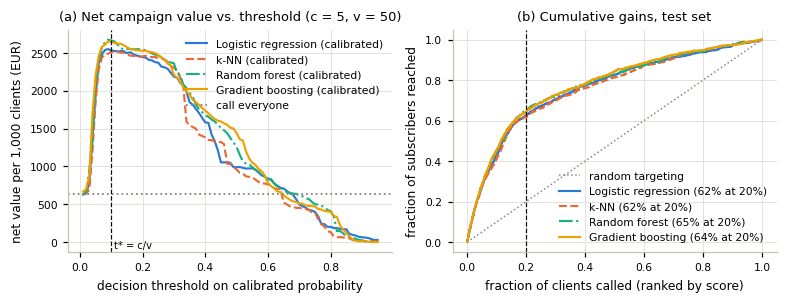

                     at_20pct  at_40pct  lift_at_10pct
Logistic regression     0.623     0.774          4.278
k-NN                    0.620     0.762          4.149
Random forest           0.651     0.779          4.494
Gradient boosting       0.644     0.782          4.569


In [15]:
# Gains (cumulative capture) curves and the value-vs-threshold curves on the test set.
def gains_curve(y_true, p):
    order = np.argsort(-p, kind="stable"); ys = y_true[order]
    return np.arange(1, len(ys) + 1) / len(ys), np.cumsum(ys) / ys.sum()

capture = {}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
ax = axes[0]
for name in P_OOF:
    st = MODEL_STYLE[name]
    ax.plot(THRESHOLDS, value_curve(y_test, P_TEST[name + " (calibrated)"]), color=st["color"], ls=st["ls"], lw=1.4, label=f"{name} (calibrated)")
ax.axhline(strategies.loc[strategies["strategy"].str.startswith("Call everyone"), "net value per 1000"].iloc[0],
           color="#898781", ls=":", lw=1.2, label="call everyone")
ax.axvline(T_STAR, color="#0b0b0b", lw=0.8, ls="--"); ax.text(T_STAR + 0.01, ax.get_ylim()[0] + 50, "t* = c/v", fontsize=6.5)
ax.set_xlabel("decision threshold on calibrated probability"); ax.set_ylabel("net value per 1,000 clients (EUR)")
ax.set_title(f"(a) Net campaign value vs. threshold (c = {COST_CONTACT:.0f}, v = {VALUE_SUB:.0f})"); ax.legend(loc="upper right")
ax = axes[1]
ax.plot([0, 1], [0, 1], color="#898781", ls=":", lw=1, label="random targeting")
for name in P_OOF:
    st = MODEL_STYLE[name]
    fc, fp_ = gains_curve(y_test, P_TEST[name])
    capture[name] = {"at_20pct": float(fp_[int(0.2 * n_test) - 1]), "at_40pct": float(fp_[int(0.4 * n_test) - 1]),
                     "lift_at_10pct": float(fp_[int(0.1 * n_test) - 1] / 0.10)}
    ax.plot(fc, fp_, color=st["color"], ls=st["ls"], lw=1.4, label=f"{name} ({100*capture[name]['at_20pct']:.0f}% at 20%)")
ax.axvline(0.2, color="#0b0b0b", lw=0.8, ls="--")
ax.set_xlabel("fraction of clients called (ranked by score)"); ax.set_ylabel("fraction of subscribers reached")
ax.set_title("(b) Cumulative gains, test set"); ax.legend(loc="lower right")
fig.tight_layout()
finish_figure(fig, "fig_cost_gains")
RESULTS["cost"]["capture"] = capture
print(pd.DataFrame(capture).T.round(3))

In [16]:
# Sensitivity of the recommendation to the cost ratio c/v (calibrated models at t* = c/v, versus calling everyone).
sens_rows = []
for ratio in COST_RATIOS_SENS:
    c = ratio * VALUE_SUB
    row = {"cost ratio c/v": ratio, "call everyone": campaign_value(y_test, np.ones(n_test), 0.5, c, VALUE_SUB)["net value per 1000"]}
    for name in P_OOF:
        cv_ = campaign_value(y_test, P_TEST[name + " (calibrated)"], ratio, c, VALUE_SUB)
        row[name] = cv_["net value per 1000"]
        row[name + " call rate"] = cv_["call rate"]
    sens_rows.append(row)
cost_sens = pd.DataFrame(sens_rows)
cost_rep = cost_sens[["cost ratio c/v", "call everyone"] + list(P_OOF) + [BEST + " call rate"]].copy()
cost_rep["cost ratio c/v"] = cost_rep["cost ratio c/v"].map("{:.2f}".format)
for c in ["call everyone"] + list(P_OOF):
    cost_rep[c] = cost_rep[c].map(lambda v: f"{v:,.0f}")
cost_rep[BEST + " call rate"] = cost_rep[BEST + " call rate"].map("{:.2f}".format)
cost_rep.columns = ["c/v", "call everyone"] + [m.replace("Logistic regression", "LR").replace("Random forest", "RF").replace("Gradient boosting", "GB") for m in P_OOF] + [f"call rate ({BEST.replace('Logistic regression', 'LR').replace('Random forest', 'RF').replace('Gradient boosting', 'GB')})"]
save_table(cost_rep, "cost_ratio_sensitivity", align="l" + "r" * (len(cost_rep.columns) - 1))
display(cost_sens.round(3))
RESULTS["cost"]["ratio_sensitivity"] = cost_sens.round(4).to_dict("records")

,cost ratio c/v,call everyone,Logistic regression,Logistic regression call rate,k-NN,k-NN call rate,Random forest,Random forest call rate,Gradient boosting,Gradient boosting call rate
0,0.05,3133.803,3446.151,0.606,3380.889,0.612,3416.100,0.518,3470.738,0.506
1,0.10,633.803,2533.997,0.206,2518.213,0.196,2668.164,0.219,2646.916,0.208
2,0.20,-4366.197,1702.283,0.149,1694.998,0.152,1809.131,0.148,1786.061,0.149
3,0.30,-9366.197,1002.914,0.119,948.276,0.136,1083.657,0.128,1068.480,0.114


## 10. Operating points and confusion matrices

The threshold-based metrics below show how the same model behaves under different decision policies.
A threshold of 0.5 (the library default) is almost never appropriate for a rare outcome with asymmetric costs.

,model,policy,accuracy,balanced accuracy,precision,recall,specificity,F1,TP,FP,FN,TN,net value per 1000
0,Logistic regression,"raw, t = 0.5",0.899,0.604,0.659,0.223,0.985,0.333,207,107,721,7201,1066.051
1,Logistic regression,"raw, OOF-tuned t = 0.13",0.842,0.741,0.375,0.611,0.871,0.465,567,943,361,6365,2525.498
2,Logistic regression,"calibrated, t* = 0.10",0.824,0.740,0.346,0.633,0.848,0.447,587,1109,341,6199,2533.997
3,k-NN,"raw, t = 0.5",0.898,0.603,0.645,0.221,0.985,0.329,205,113,723,7195,1051.481
4,k-NN,"raw, OOF-tuned t = 0.11",0.827,0.736,0.349,0.620,0.853,0.447,575,1072,353,6236,2490.894
5,k-NN,"calibrated, t* = 0.10",0.831,0.739,0.357,0.621,0.858,0.454,576,1036,352,6272,2518.213
6,Random forest,"raw, t = 0.5",0.902,0.621,0.668,0.258,0.984,0.372,239,119,689,7189,1233.609
7,Random forest,"raw, OOF-tuned t = 0.09",0.814,0.755,0.337,0.679,0.831,0.451,630,1237,298,6071,2691.234
8,Random forest,"calibrated, t* = 0.10",0.819,0.753,0.343,0.668,0.838,0.454,620,1185,308,6123,2668.164
9,Gradient boosting,"raw, t = 0.5",0.902,0.620,0.662,0.258,0.983,0.371,239,122,689,7186,1231.787


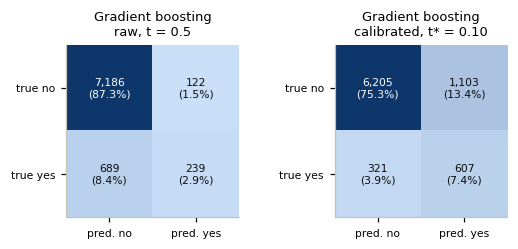

In [17]:
op_rows, cms = [], {}
for name in P_OOF:
    for policy, p, t in [("raw, t = 0.5", P_TEST[name], 0.5),
                         (f"raw, OOF-tuned t = {T_TUNED[name]:.2f}", P_TEST[name], T_TUNED[name]),
                         (f"calibrated, t* = {T_STAR:.2f}", P_TEST[name + " (calibrated)"], T_STAR)]:
        pred = (p >= t).astype(int)
        cm = confusion_matrix(y_test, pred, labels=[0, 1])
        cms[(name, policy)] = cm
        tn, fp, fn, tp = cm.ravel()
        op_rows.append({"model": name, "policy": policy, "accuracy": (tp + tn) / n_test,
                        "balanced accuracy": balanced_accuracy_score(y_test, pred),
                        "precision": precision_score(y_test, pred, zero_division=0),
                        "recall": recall_score(y_test, pred), "specificity": tn / (tn + fp),
                        "F1": f1_score(y_test, pred, zero_division=0), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                        "net value per 1000": campaign_value(y_test, p, t)["net value per 1000"]})
operating_points = pd.DataFrame(op_rows)
save_table(operating_points, "operating_points", float_fmt="{:.3f}")
display(operating_points.round(3))
RESULTS["operating_points"] = operating_points.round(4).to_dict("records")
# Compact report version: the selected model under all three policies, other models at the calibrated t*.
op_rep = operating_points[(operating_points["model"] == BEST) | operating_points["policy"].str.startswith("calibrated")].copy()
op_rep = op_rep[["model", "policy", "balanced accuracy", "precision", "recall", "F1", "net value per 1000"]]
op_rep["net value per 1000"] = op_rep["net value per 1000"].map(lambda v: f"{v:,.0f}")
op_rep["policy"] = op_rep["policy"].str.replace("OOF-tuned ", "tuned ", regex=False)
op_rep.columns = ["model", "policy", "bal. acc.", "precision", "recall", "F1", "net value / 1,000"]
save_table(op_rep, "operating_points_report", float_fmt="{:.3f}", align="llrrrrr")

# Confusion matrices of the selected model at the default threshold and at the calibrated Bayes threshold (report table).
cm05, cmt = cms[(BEST, "raw, t = 0.5")], cms[(BEST, f"calibrated, t* = {T_STAR:.2f}")]
(TAB_DIR / "confusion_report.tex").write_text("\n".join([
    "\\begin{tabular}{lrrcrr}", "\\toprule",
    f" & \\multicolumn{{2}}{{c}}{{raw, $t=0.5$}} & & \\multicolumn{{2}}{{c}}{{calibrated, $t^\\star={T_STAR:.2f}$}} \\\\",
    "\\cmidrule{2-3}\\cmidrule{5-6}",
    " & pred.\\ no & pred.\\ yes & & pred.\\ no & pred.\\ yes \\\\", "\\midrule",
    f"true no & {cm05[0,0]:,} & {cm05[0,1]:,} & & {cmt[0,0]:,} & {cmt[0,1]:,} \\\\",
    f"true yes & {cm05[1,0]:,} & {cm05[1,1]:,} & & {cmt[1,0]:,} & {cmt[1,1]:,} \\\\",
    "\\bottomrule", "\\end{tabular}"]), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(5.0, 2.3))
for ax, policy in zip(axes, ["raw, t = 0.5", f"calibrated, t* = {T_STAR:.2f}"]):
    cm = cms[(BEST, policy)]
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({100*cm[i, j]/cm.sum():.1f}%)", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 * cm.max() else "#0b0b0b")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["pred. no", "pred. yes"]); ax.set_yticklabels(["true no", "true yes"])
    ax.set_title(f"{BEST}\n{policy}"); ax.grid(False)
fig.tight_layout()
finish_figure(fig, "fig_confusion")

## 11. Model interpretation

* **Logistic-regression coefficients** (on standardised numeric and one-hot features) give signed, directly
  interpretable effects.
* **Permutation importance** of the selected model measures the drop in test-set average precision when one
  input column is shuffled (10 repeats); it is model-agnostic and accounts for interactions.
* **Partial-dependence plots** show the average predicted probability as a function of one input.

,feature,mean drop in AP,sd
9,nr.employed,0.1670,0.0064
17,month,0.0517,0.0033
5,emp.var.rate,0.0254,0.0040
16,contact,0.0228,0.0043
4,prev_contacted,0.0184,0.0030
19,poutcome,0.0172,0.0028
18,day_of_week,0.0146,0.0022
8,euribor3m,0.0099,0.0030
1,campaign,0.0085,0.0020
0,age,0.0054,0.0011


permutation importance computed in 13 s


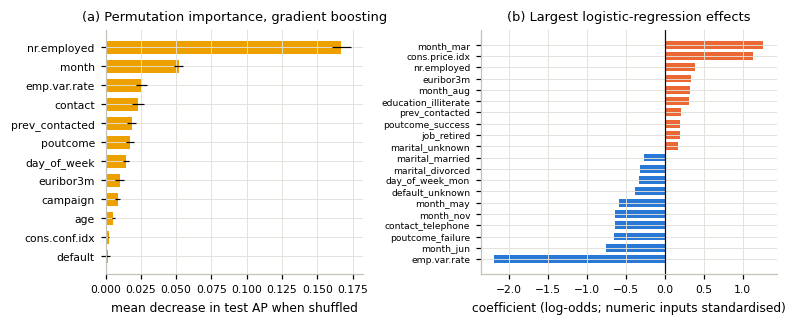

In [18]:
lr = fitted["Logistic regression"]
feat_names = lr.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=[f.replace("num__", "").replace("cat__", "") for f in feat_names])
coef_table = coefs.sort_values()
top_coef = pd.concat([coef_table.head(10), coef_table.tail(10)])
save_table(top_coef.rename("coefficient").reset_index().rename(columns={"index": "feature"}), "lr_coefficients", float_fmt="{:.3f}")
RESULTS["lr_top_coefficients"] = top_coef.round(4).to_dict()

t0 = time.time()
perm = permutation_importance(fitted[BEST], X_test, y_test, scoring="average_precision",
                              n_repeats=3 if FAST else 10, random_state=SEED, n_jobs=1)
perm_imp = pd.DataFrame({"feature": FEATURES, "mean drop in AP": perm.importances_mean, "sd": perm.importances_std}).sort_values("mean drop in AP", ascending=False)
save_table(perm_imp, "permutation_importance", float_fmt="{:.4f}")
display(perm_imp.round(4))
print(f"permutation importance computed in {time.time()-t0:.0f} s")
RESULTS["permutation_importance"] = perm_imp.set_index("feature")["mean drop in AP"].round(5).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
pi = perm_imp.head(12).iloc[::-1]
ax.barh(pi["feature"], pi["mean drop in AP"], xerr=pi["sd"], color=MODEL_STYLE[BEST]["color"], height=0.7, error_kw={"lw": 0.8})
ax.set_xlabel("mean decrease in test AP when shuffled"); ax.set_title(f"(a) Permutation importance, {BEST.lower()}")
ax = axes[1]
tc = top_coef
ax.barh(tc.index, tc.values, color=[C_YES if v > 0 else C_NO for v in tc.values], height=0.7)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("coefficient (log-odds; numeric inputs standardised)"); ax.set_title("(b) Largest logistic-regression effects")
ax.tick_params(axis="y", labelsize=6)
fig.tight_layout()
finish_figure(fig, "fig_importance")

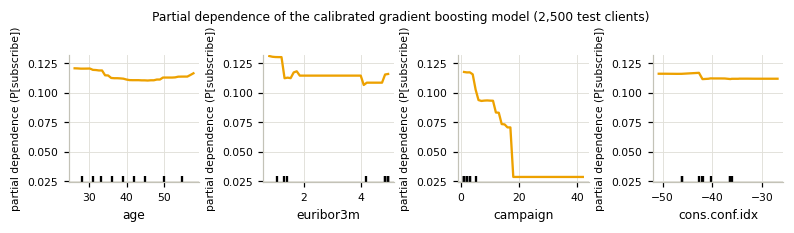

In [19]:
pdp_features = ["age", "euribor3m", "campaign", "cons.conf.idx"]
X_pdp = X_test.sample(n=min(2500, len(X_test)), random_state=SEED).astype({c: float for c in NUM})  # float dtype so grid values can be assigned
fig, axes = plt.subplots(1, len(pdp_features), figsize=(7.2, 2.0))
PartialDependenceDisplay.from_estimator(CALIBRATED[BEST], X_pdp, features=pdp_features, kind="average",
                                        grid_resolution=40, ax=axes, line_kw={"color": MODEL_STYLE[BEST]["color"], "lw": 1.5})
for ax in axes:
    ax.set_ylabel("partial dependence (P[subscribe])", fontsize=7)
fig.suptitle(f"Partial dependence of the calibrated {BEST.lower()} model (2,500 test clients)", fontsize=8, y=1.02)
fig.tight_layout()
finish_figure(fig, "fig_pdp")

## 12. Error analysis and subgroup performance

We analyse the **recommended configuration** (the selected model, isotonic-calibrated, decision threshold
t* = c/v): concrete false negatives and false positives, where errors concentrate, and performance by subgroup.

In [20]:
FINAL_NAME = f"{BEST} (calibrated)"
p_final = P_TEST[FINAL_NAME]
pred_final = (p_final >= T_STAR).astype(int)
test_df = X_test.copy()
test_df["y"] = y_test; test_df["p_hat"] = p_final; test_df["called"] = pred_final
test_df["error"] = np.select([(test_df.y == 1) & (test_df.called == 0), (test_df.y == 0) & (test_df.called == 1)],
                             ["false negative", "false positive"], "correct")
show_cols = ["age", "job", "education", "contact", "month", "poutcome", "campaign", "previous", "euribor3m", "nr.employed", "y", "p_hat"]
fn_examples = test_df[test_df.error == "false negative"].nsmallest(5, "p_hat")[show_cols]
fp_examples = test_df[test_df.error == "false positive"].nlargest(5, "p_hat")[show_cols]
print("Most confident FALSE NEGATIVES (subscribed, but model would not call):"); display(fn_examples.round(3))
print("Most confident FALSE POSITIVES (called, did not subscribe):"); display(fp_examples.round(3))
examples = pd.concat([fn_examples.assign(kind="FN"), fp_examples.assign(kind="FP")])
examples = examples[["kind"] + show_cols]
save_table(examples, "error_examples", float_fmt="{:.2f}")

# Correct decisions for comparison: the most confident true positives (called and subscribed) and the most
# confident true negatives (not called and did not subscribe).
tp_examples = test_df[(test_df.y == 1) & (test_df.called == 1)].nlargest(5, "p_hat")[show_cols]
tn_examples = test_df[(test_df.y == 0) & (test_df.called == 0)].nsmallest(5, "p_hat")[show_cols]
print("Most confident CORRECT decisions, true positives (called, subscribed):"); display(tp_examples.round(3))
print("Most confident CORRECT decisions, true negatives (not called, did not subscribe):"); display(tn_examples.round(3))
correct = pd.concat([tp_examples.assign(kind="TP"), tn_examples.assign(kind="TN")])[["kind"] + show_cols]
save_table(correct, "correct_examples", float_fmt="{:.2f}")
RESULTS["prediction_examples"] = {k: v["p_hat"].round(4).tolist() for k, v in
                                  [("TP", tp_examples), ("TN", tn_examples), ("FN", fn_examples), ("FP", fp_examples)]}

# Compact report version: two of each kind (correct and incorrect decisions).
ex_rep = pd.concat([tp_examples.head(2).assign(kind="TP"), tn_examples.head(2).assign(kind="TN"),
                    fn_examples.head(2).assign(kind="FN"), fp_examples.head(2).assign(kind="FP")])
ex_rep = ex_rep[["kind", "age", "job", "contact", "month", "poutcome", "campaign", "euribor3m", "p_hat"]].copy()
ex_rep["p_hat"] = ex_rep["p_hat"].map("{:.3f}".format); ex_rep["euribor3m"] = ex_rep["euribor3m"].map("{:.2f}".format)
ex_rep.columns = ["type", "age", "job", "contact", "month", "poutcome", "calls", "euribor3m", "prob."]
save_table(ex_rep, "prediction_examples_report", align="llllllrrr")

# Where do the errors concentrate?  Recall / precision of the final rule by month and previous outcome.
def rule_metrics(g):
    tp = ((g.y == 1) & (g.called == 1)).sum(); fn = ((g.y == 1) & (g.called == 0)).sum(); fp = ((g.y == 0) & (g.called == 1)).sum()
    return pd.Series({"n": len(g), "prevalence": g.y.mean(), "call rate": g.called.mean(),
                      "recall": tp / (tp + fn) if (tp + fn) else np.nan, "precision": tp / (tp + fp) if (tp + fp) else np.nan,
                      "AP": average_precision_score(g.y, g.p_hat) if g.y.sum() >= 20 and g.y.sum() < len(g) else np.nan,
                      "mean p_hat": g.p_hat.mean()})

by_month = test_df.groupby("month").apply(rule_metrics, include_groups=False).loc[[m for m in MONTH_ORDER if m in test_df.month.unique()]]
display(by_month.round(3))
by_pout = test_df.groupby("poutcome").apply(rule_metrics, include_groups=False)
display(by_pout.round(3))

Most confident FALSE NEGATIVES (subscribed, but model would not call):


,age,job,education,contact,month,poutcome,campaign,previous,euribor3m,nr.employed,y,p_hat
3218,39,blue-collar,basic.9y,telephone,may,nonexistent,23,0,4.860,5191.0,1,0.000
876,44,blue-collar,basic.4y,telephone,may,nonexistent,1,0,4.856,5191.0,1,0.017
139,45,blue-collar,basic.9y,telephone,may,nonexistent,1,0,4.857,5191.0,1,0.019
4267,47,blue-collar,unknown,telephone,may,nonexistent,1,0,4.856,5191.0,1,0.021
6361,45,blue-collar,basic.6y,telephone,may,nonexistent,6,0,4.857,5191.0,1,0.022


Most confident FALSE POSITIVES (called, did not subscribe):


,age,job,education,contact,month,poutcome,campaign,previous,euribor3m,nr.employed,y,p_hat
39231,39,admin.,university.degree,cellular,mar,success,1,1,0.650,5008.7,0,0.939
39288,33,self-employed,university.degree,cellular,mar,success,1,1,0.644,5008.7,0,0.862
39633,50,admin.,high.school,cellular,may,success,2,5,0.682,5008.7,0,0.858
40230,32,technician,university.degree,cellular,jul,success,1,2,0.885,4991.6,0,0.831
40154,32,admin.,university.degree,cellular,jul,success,2,1,0.846,4991.6,0,0.828


Most confident CORRECT decisions, true positives (called, subscribed):


,age,job,education,contact,month,poutcome,campaign,previous,euribor3m,nr.employed,y,p_hat
40457,92,retired,unknown,cellular,aug,success,1,4,0.903,4991.6,1,0.923
40209,37,unemployed,university.degree,cellular,jul,success,1,2,0.881,4991.6,1,0.914
39625,58,admin.,high.school,cellular,may,success,1,1,0.682,5008.7,1,0.886
39526,52,admin.,unknown,telephone,apr,success,1,1,0.654,5008.7,1,0.877
39591,37,technician,university.degree,cellular,may,success,1,4,0.677,5008.7,1,0.877


Most confident CORRECT decisions, true negatives (not called, did not subscribe):


,age,job,education,contact,month,poutcome,campaign,previous,euribor3m,nr.employed,y,p_hat
4138,52,management,basic.4y,telephone,may,nonexistent,35,0,4.858,5191.0,0,0.0
11032,38,blue-collar,basic.4y,telephone,jun,nonexistent,41,0,4.962,5228.1,0,0.0
11826,53,blue-collar,basic.4y,telephone,jun,nonexistent,18,0,4.959,5228.1,0,0.0
18679,31,services,high.school,cellular,jul,nonexistent,35,0,4.968,5228.1,0,0.0
11393,51,services,high.school,telephone,jun,nonexistent,28,0,4.959,5228.1,0,0.0


,n,prevalence,call rate,recall,precision,AP,mean p_hat
month,,,,,,,
mar,107.0,0.523,1.000,1.000,0.523,0.661,0.503
apr,504.0,0.198,0.673,0.880,0.260,0.520,0.210
may,2730.0,0.067,0.135,0.451,0.226,0.308,0.064
jun,1069.0,0.101,0.179,0.704,0.398,0.430,0.103
jul,1428.0,0.084,0.071,0.350,0.416,0.333,0.091
aug,1277.0,0.095,0.148,0.579,0.370,0.431,0.104
sep,116.0,0.509,1.000,1.000,0.509,0.792,0.452
oct,153.0,0.438,1.000,1.000,0.438,0.642,0.449
nov,816.0,0.115,0.140,0.511,0.421,0.433,0.099


,n,prevalence,call rate,recall,precision,AP,mean p_hat
poutcome,,,,,,,
failure,866.0,0.145,0.342,0.738,0.314,0.389,0.150
nonexistent,7097.0,0.088,0.161,0.541,0.297,0.350,0.087
success,273.0,0.641,1.000,1.000,0.641,0.800,0.656


,variable,level,n,prevalence,call rate,recall,precision,AP,mean p_hat
0,age band,18-29,1127,0.163,0.364,0.734,0.329,0.435,0.162
1,age band,30-44,4470,0.091,0.165,0.578,0.320,0.413,0.095
2,age band,45-59,2401,0.095,0.150,0.566,0.357,0.478,0.092
3,age band,60+,237,0.456,0.844,0.991,0.535,0.754,0.408
4,contact,cellular,5237,0.147,0.288,0.702,0.358,0.503,0.145
5,contact,telephone,2999,0.053,0.067,0.421,0.332,0.336,0.055
6,previous outcome,failure,866,0.145,0.342,0.738,0.314,0.389,0.150
7,previous outcome,nonexistent,7097,0.088,0.161,0.541,0.297,0.350,0.087
8,previous outcome,success,273,0.641,1.000,1.000,0.641,0.800,0.656
9,education,basic.4y,839,0.100,0.136,0.679,0.500,0.617,0.094


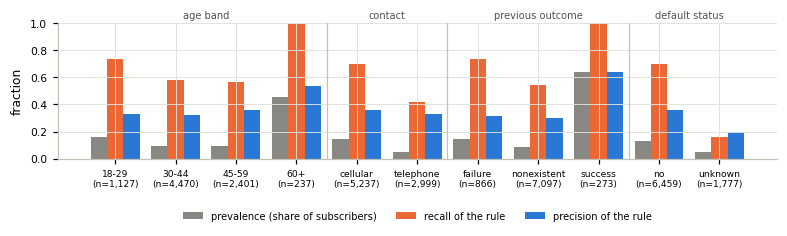

In [21]:
test_df["age band"] = pd.cut(test_df["age"], bins=[17, 29, 44, 59, 120], labels=["18-29", "30-44", "45-59", "60+"])
subgroup_specs = [("age band", "age band"), ("contact", "contact"), ("poutcome", "previous outcome"),
                  ("education", "education"), ("job", "job"), ("default", "default status")]
sub_rows = []
for col, label in subgroup_specs:
    g = test_df.groupby(col, observed=True).apply(rule_metrics, include_groups=False)
    g.insert(0, "level", g.index.astype(str)); g.insert(0, "variable", label)
    sub_rows.append(g.reset_index(drop=True))
subgroups = pd.concat(sub_rows, ignore_index=True)
subgroups["n"] = subgroups["n"].astype(int)
save_table(subgroups, "subgroup_performance", float_fmt="{:.3f}")
display(subgroups.round(3))
RESULTS["subgroups"] = subgroups.round(4).to_dict("records")
RESULTS["error_patterns"] = {"by_month": by_month.round(4).to_dict("index"), "by_poutcome": by_pout.round(4).to_dict("index")}
RESULTS["final_rule"] = {"model": FINAL_NAME, "threshold": T_STAR, **{k: float(v) for k, v in campaign_value(y_test, p_final, T_STAR).items()}}

# Subgroup figure for the report (recall and call rate by age band and contact channel).
sg = subgroups[subgroups["variable"].isin(["age band", "contact", "previous outcome", "default status"])].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.2, 2.4))
xpos = np.arange(len(sg)); w = 0.27
ax.bar(xpos - w, sg["prevalence"], w, color="#898781", label="prevalence (share of subscribers)")
ax.bar(xpos, sg["recall"], w, color=C_YES, label="recall of the rule")
ax.bar(xpos + w, sg["precision"], w, color=C_NO, label="precision of the rule")
ax.set_xticks(xpos); ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(sg["level"], sg["n"])], fontsize=6)
# vertical separators between subgroup variables, with the variable name above
bounds = sg.groupby("variable", sort=False).size().cumsum().tolist()
start = 0
for var, end in zip(sg["variable"].unique(), bounds):
    ax.text((start + end - 1) / 2, 1.02, var, ha="center", va="bottom", fontsize=6.5, color="#52514e")
    if end < len(sg):
        ax.axvline(end - 0.5, color="#c3c2b7", lw=0.8)
    start = end
ax.set_ylabel("fraction"); ax.set_ylim(0, 1.0)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32), fontsize=6.5)
fig.tight_layout()
finish_figure(fig, "fig_subgroups")

## 13. Sensitivity analyses: the effect of changing important modelling choices

1. **Leakage check:** re-fit the selected model and logistic regression *with* `duration` to quantify how much
   an unrealistic feature inflates the scores.
2. **Temporal validation:** instead of a random split, train on the chronologically first 80% of clients and
   test on the last 20%, which mimics deployment on a future campaign under drift.
3. **Class weighting:** re-fit with `class_weight = "balanced"` to see how re-weighting changes ranking,
   calibration, and the cost-based decision.

In [22]:
def eval_probs(y_true, p):
    return {"AP": average_precision_score(y_true, p), "ROC-AUC": roc_auc_score(y_true, p),
            "Brier": brier_score_loss(y_true, p), "ECE": ece_score(y_true, p)}

sens_rows = []
# --- (1) leakage: add duration ---
Xtr_d = df.loc[X_train.index, FEATURES + ["duration"]]; Xte_d = df.loc[X_test.index, FEATURES + ["duration"]]
for name in ["Logistic regression", BEST]:
    base = clone(fitted[name])
    base.set_params(pre=make_preprocessor(PRE_KIND[name], num_cols=NUM + ["duration"]))
    base.fit(Xtr_d, y_train)
    m = eval_probs(y_test, base.predict_proba(Xte_d)[:, 1])
    sens_rows.append({"experiment": "leakage: with duration", "model": name, **m})
    sens_rows.append({"experiment": "main: without duration", "model": name, **eval_probs(y_test, P_TEST[name])})

# --- (2) temporal split (file is ordered by date) ---
cut = int(0.8 * len(df))
tr_idx, te_idx = df.index[:cut], df.index[cut:]
y_tr_t, y_te_t = y[tr_idx], y[te_idx]
temporal_info = {"train_pos_rate": float(y_tr_t.mean()), "test_pos_rate": float(y_te_t.mean()),
                 "test_nr_employed_unseen_share": float((~df.loc[te_idx, "nr.employed"].isin(df.loc[tr_idx, "nr.employed"].unique())).mean()),
                 "test_euribor_unseen_share": float((~df.loc[te_idx, "euribor3m"].isin(df.loc[tr_idx, "euribor3m"].unique())).mean())}
print("temporal split:", temporal_info)
temporal_models = {}
for name in ["Logistic regression", BEST]:
    m_t = clone(fitted[name]).fit(X.loc[tr_idx], y_tr_t)
    p_t = m_t.predict_proba(X.loc[te_idx])[:, 1]
    temporal_models[name] = p_t
    sens_rows.append({"experiment": "temporal split (last 20% as test)", "model": name, **eval_probs(y_te_t, p_t)})
cal_t = CalibratedClassifierCV(clone(fitted[BEST]), method="isotonic", cv=skf, ensemble=True).fit(X.loc[tr_idx], y_tr_t)
p_t_cal = cal_t.predict_proba(X.loc[te_idx])[:, 1]
sens_rows.append({"experiment": "temporal split, calibrated", "model": BEST, **eval_probs(y_te_t, p_t_cal)})
temporal_cost = {"call everyone": campaign_value(y_te_t, np.ones(len(y_te_t)), 0.5)["net value per 1000"],
                 f"{BEST} calibrated at t*": campaign_value(y_te_t, p_t_cal, T_STAR),
                 f"{BEST} raw at t*": campaign_value(y_te_t, temporal_models[BEST], T_STAR)}
print("temporal split, cost view:", {k: (v if isinstance(v, float) else {kk: round(vv, 3) for kk, vv in v.items()}) for k, v in temporal_cost.items()})
RESULTS["temporal"] = {**temporal_info, "cost": {k: (v if isinstance(v, float) else {kk: float(vv) for kk, vv in v.items()}) for k, v in temporal_cost.items()}}

# --- (3) class weighting ---
weighted_cost = {}
for name in ["Logistic regression", BEST]:
    m_w = clone(fitted[name])
    m_w.set_params(clf__class_weight="balanced")
    m_w.fit(X_train, y_train)
    p_w = m_w.predict_proba(X_test)[:, 1]
    sens_rows.append({"experiment": "class_weight = balanced", "model": name, **eval_probs(y_test, p_w)})
    weighted_cost[name] = {"weighted raw at t*": campaign_value(y_test, p_w, T_STAR),
                           "weighted raw at 0.5": campaign_value(y_test, p_w, 0.5),
                           "unweighted raw at 0.5": campaign_value(y_test, P_TEST[name], 0.5)}
RESULTS["class_weight_cost"] = {n: {k: {kk: float(vv) for kk, vv in v.items()} for k, v in d.items()} for n, d in weighted_cost.items()}
sensitivity = pd.DataFrame(sens_rows)
save_table(sensitivity, "sensitivity", float_fmt="{:.3f}")
display(sensitivity.round(3))
RESULTS["sensitivity"] = sensitivity.round(4).to_dict("records")

# Report tables: (a) decision quality under the temporal split, (b) effect of class weighting on the cost decision.
short = {"Logistic regression": "LR", "k-NN": "k-NN", "Random forest": "RF", "Gradient boosting": "GB"}
tmp_rows = [{"policy (temporal test set)": "call everyone", "call rate": "1.00", "precision": f"{y_te_t.mean():.2f}", "recall": "1.00",
             "net value / 1,000": f"{temporal_cost['call everyone']:,.0f}"}]
for lbl, key in [(f"{short[BEST]}, raw, t* = {T_STAR:.2f}", f"{BEST} raw at t*"), (f"{short[BEST]}, calibrated, t* = {T_STAR:.2f}", f"{BEST} calibrated at t*")]:
    v = temporal_cost[key]
    tmp_rows.append({"policy (temporal test set)": lbl, "call rate": f"{v['call rate']:.2f}", "precision": f"{v['precision']:.2f}",
                     "recall": f"{v['recall']:.2f}", "net value / 1,000": f"{v['net value per 1000']:,.0f}"})
save_table(pd.DataFrame(tmp_rows), "temporal_report", align="lrrrr")

cw_rows = []
for name in ["Logistic regression", BEST]:
    base_m = next(r for r in sens_rows if r["experiment"] == "main: without duration" and r["model"] == name)
    bal_m = next(r for r in sens_rows if r["experiment"] == "class_weight = balanced" and r["model"] == name)
    unw = campaign_value(y_test, P_TEST[name], T_STAR); w05 = weighted_cost[name]["weighted raw at t*"]
    cw_rows.append({"model": short[name], "class weight": "none", "AP": f"{base_m['AP']:.3f}", "Brier": f"{base_m['Brier']:.3f}", "ECE": f"{base_m['ECE']:.3f}",
                    "call rate": f"{unw['call rate']:.2f}", "recall": f"{unw['recall']:.2f}", "net value / 1,000": f"{unw['net value per 1000']:,.0f}"})
    cw_rows.append({"model": short[name], "class weight": "balanced", "AP": f"{bal_m['AP']:.3f}", "Brier": f"{bal_m['Brier']:.3f}", "ECE": f"{bal_m['ECE']:.3f}",
                    "call rate": f"{w05['call rate']:.2f}", "recall": f"{w05['recall']:.2f}", "net value / 1,000": f"{w05['net value per 1000']:,.0f}"})
# call rate / recall / net value refer to the raw (uncalibrated) scores thresholded at t* = c/v
save_table(pd.DataFrame(cw_rows), "class_weight_report", align="llrrrrrr")

temporal split: {'train_pos_rate': 0.06375227686703097, 'test_pos_rate': 0.3082807187955318, 'test_nr_employed_unseen_share': 0.6024769305488101, 'test_euribor_unseen_share': 0.9851869839728024}


temporal split, cost view: {'call everyone': 10414.035939776591, 'Gradient boosting calibrated at t*': {'threshold': 0.1, 'calls': 2269, 'call rate': 0.275, 'TP': 1225, 'FP': 1044, 'FN': 1314, 'TN': 4653, 'precision': 0.54, 'recall': 0.482, 'spend per 1000': 1377.489, 'subscriptions per 1000': 148.737, 'net value per 1000': 6059.373, 'misclassification cost per 1000': 7813.259}, 'Gradient boosting raw at t*': {'threshold': 0.1, 'calls': 2403, 'call rate': 0.292, 'TP': 1272, 'FP': 1131, 'FN': 1267, 'TN': 4566, 'precision': 0.529, 'recall': 0.501, 'spend per 1000': 1458.839, 'subscriptions per 1000': 154.444, 'net value per 1000': 6263.356, 'misclassification cost per 1000': 7609.276}}


,experiment,model,AP,ROC-AUC,Brier,ECE
0,leakage: with duration,Logistic regression,0.595,0.935,0.064,0.031
1,main: without duration,Logistic regression,0.449,0.796,0.079,0.008
2,leakage: with duration,Gradient boosting,0.667,0.950,0.056,0.008
3,main: without duration,Gradient boosting,0.481,0.810,0.076,0.005
4,temporal split (last 20% as test),Logistic regression,0.526,0.748,0.191,0.097
5,temporal split (last 20% as test),Gradient boosting,0.482,0.676,0.232,0.190
6,"temporal split, calibrated",Gradient boosting,0.482,0.665,0.234,0.190
7,class_weight = balanced,Logistic regression,0.444,0.797,0.162,0.275
8,class_weight = balanced,Gradient boosting,0.476,0.811,0.155,0.266


## 14. Export of results and summary

In [23]:
def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

RESULTS["runtime_minutes"] = round((time.time() - T0) / 60, 1)
(OUT_DIR / "results.json").write_text(json.dumps(RESULTS, indent=2, default=_json_default), encoding="utf-8")
print(f"Wrote {OUT_DIR/'results.json'}; figures in {FIG_DIR}; tables in {TAB_DIR}. Total runtime {RESULTS['runtime_minutes']} min.")

best_test = RESULTS["test"][BEST]
final = RESULTS["final_rule"]
everyone = RESULTS["cost"]["strategies"]["Call everyone (current practice)"]
print(f"""
SUMMARY
-------
Selected model (by CV average precision): {BEST}
Test AP = {best_test['AP']['value']:.3f} [{best_test['AP']['ci_low']:.3f}, {best_test['AP']['ci_high']:.3f}], ROC-AUC = {best_test['ROC-AUC']['value']:.3f}
Final decision rule: {FINAL_NAME}, call if p >= {T_STAR:.2f}
  -> calls {100*final['call rate']:.1f}% of clients, reaches {100*final['recall']:.1f}% of subscribers, precision {100*final['precision']:.1f}%
  -> net value {final['net value per 1000']:.0f} EUR per 1,000 clients vs {everyone['net value per 1000']:.0f} EUR when calling everyone
""")

Wrote C:\Users\Andrew Aurand\ccsi5810_midterm_group\code\outputs\results.json; figures in C:\Users\Andrew Aurand\ccsi5810_midterm_group\code\outputs\figures; tables in C:\Users\Andrew Aurand\ccsi5810_midterm_group\code\outputs\tables. Total runtime 5.9 min.

SUMMARY
-------
Selected model (by CV average precision): Gradient boosting
Test AP = 0.481 [0.445, 0.515], ROC-AUC = 0.810
Final decision rule: Gradient boosting (calibrated), call if p >= 0.10
  -> calls 20.8% of clients, reaches 65.4% of subscribers, precision 35.5%
  -> net value 2647 EUR per 1,000 clients vs 634 EUR when calling everyone



### Reproducibility notes and generative-AI disclosure

* **Data path and download instructions** are given at the top of the notebook; no manual data edits are needed.
* **Seeds** are fixed (`SEED = 5810`) for the split, folds, model initialisation, randomised search, bootstrap,
  permutation importance and partial-dependence subsampling.
* **Runtime:** roughly 10-20 minutes on an 8-core laptop for the full configuration.
* **Outputs** (`outputs/figures`, `outputs/tables`, `outputs/results.json`) are regenerated on every run and are
  the only source of the numbers in the report.
* **Generative-AI disclosure:** this notebook and the accompanying report were drafted with assistance from
  Anthropic's Claude (Claude Code), which was used to write and debug the analysis code, to structure the
  notebook, and to draft and edit the report text and LaTeX. All group members reviewed the code and results and
  are responsible for the methodological choices, the interpretation, and the conclusions.